# Analisis Eksperimen — G09 Sepakat

Notebook ini membaca hasil run di `output/**/*.json` (ditulis oleh `src/experiments.py` atau `src/main.py`) dan
menampilkan:

1. tabel hasil per bagian EXPERIMENTS §4,
2. plot per algoritma (objective vs iterasi, `e^(ΔE/T)` untuk SA, max/mean populasi untuk GA),
3. state awal dan akhir run terbaik tiap algoritma,
4. ringkasan antar-algoritma.

Tidak ada search yang dijalankan di sini; semua dibuat dari JSON. Jalankan eksperimen dulu dari root repo:

```bash
python src/experiments.py
```

Variabel lingkungan opsional: `EXPERIMENTS_OUTPUT` (folder hasil, default `output/`) dan `EXPERIMENTS_QUICK=1`
(membaca hasil `python src/experiments.py --quick`).

In [1]:
import io
import os
import sys
from itertools import accumulate
from pathlib import Path

from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure

# root repo: notebook bisa dibuka dari folder notebooks/ atau dari root
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").is_file())
sys.path.insert(0, str(ROOT / "src"))

from config import OUTPUT_DIR
from core.problem import load_problem
from experiments import comparison_groups, load_result, machine_info, planned_runs, summary_sections
from visualization.plots import plot_objective, plot_run, plot_summary
from visualization.state_view import draw_state

OUT = Path(os.environ.get("EXPERIMENTS_OUTPUT", OUTPUT_DIR))
QUICK = os.environ.get("EXPERIMENTS_QUICK") == "1"


def show(fig):
    """Tampilkan Figure matplotlib (modul visualisasi tidak memakai pyplot), lalu tutup supaya memorinya lepas."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110)
    fig.clear()
    display(Image(data=buffer.getvalue()))


print("output :", OUT)
print("mesin  :", machine_info())

output : C:\Users\gisel\Documents\IF3070_G09_Sepakat\output
mesin  : Windows-11-10.0.26200-SP0 | CPU Intel64 Family 6 Model 186 Stepping 3, GenuineIntel (12 thread) | Python 3.14.3


## 1. Memuat hasil

Semua `output/**/*.json` dibaca, lalu dicocokkan dengan rencana run di `experiments.planned_runs()` supaya tiap
hasil tahu grupnya (bagian EXPERIMENTS). Run yang belum ada (misalnya Bonus 1 selama objective ETA belum
tersedia) ditampilkan di bawah.

In [2]:
files = sorted(OUT.rglob("*.json"))
results = {path.relative_to(OUT).with_suffix("").as_posix(): load_result(path) for path in files}

plan = planned_runs(quick=QUICK)
pairs = [(run, results[f"{run.algo}/{run.run_id}"]) for run in plan if f"{run.algo}/{run.run_id}" in results]
planned = {f"{run.algo}/{run.run_id}" for run in plan}
missing = [f"{run.algo}/{run.run_id}" for run in plan if f"{run.algo}/{run.run_id}" not in results]
extra = sorted(set(results) - planned)

print(f"{len(files)} file JSON, {len(pairs)} dari {len(plan)} run yang direncanakan")
print("belum ada :", ", ".join(missing) or "-")
print("di luar rencana (mis. run manual lewat CLI):", ", ".join(extra) or "-")

33 file JSON, 33 dari 36 run yang direncanakan
belum ada : steepest/main_eta_seed1, steepest/main_eta_seed2, steepest/main_eta_seed3
di luar rencana (mis. run manual lewat CLI): -


## 2. Tabel per bagian EXPERIMENTS §4

Kolomnya sama dengan tabel di `docs/EXPERIMENTS.md`, jadi bisa langsung disalin. Isi yang sama juga ditulis
ke `output/summary.md` oleh runner.

In [3]:
display(Markdown("\n".join(summary_sections(pairs))))


### 4.1 Hill-Climbing - Steepest Ascent

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | Evals | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 982 | 982 | True | 5.1% | 16 | 208452 | 5.628 |
| 2 | 2 | -50553 | 978 | 978 | True | 5.5% | 20 | 258031 | 9.368 |
| 3 | 3 | -28402 | 902 | 902 | True | 12.9% | 17 | 221238 | 6.997 |
| **mean ± std** |  |  | 954.0 ± 45.1 | 954.0 ± 45.1 |  |  |  |  | 7.331 ± 1.892 |

### 4.2 Hill-Climbing - Stochastic (Bonus 2)

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | Evals | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 778 | 778 | True | 24.8% | 36486 | 36486 | 0.850 |
| 2 | 2 | -50553 | 876 | 876 | True | 15.4% | 32510 | 32510 | 0.854 |
| 3 | 3 | -28402 | 771 | 771 | True | 25.5% | 24504 | 24504 | 1.214 |
| **mean ± std** |  |  | 808.3 ± 58.7 | 808.3 ± 58.7 |  |  |  |  | 0.973 ± 0.209 |

### 4.3 Hill-Climbing - Sideways Move

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | #Sideways | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 982 | 982 | True | 5.1% | 116 | 100 | 48.765 |
| 2 | 2 | -50553 | 978 | 978 | True | 5.5% | 120 | 100 | 49.008 |
| 3 | 3 | -28402 | 960 | 960 | True | 7.2% | 118 | 100 | 48.126 |
| **mean ± std** |  |  | 973.3 ± 11.7 | 973.3 ± 11.7 |  |  |  |  | 48.633 ± 0.455 |

### 4.4 Hill-Climbing - Random Restart

| Run | Seed | Obj akhir | Fee | Feasible | Gap UB | #Restart | Iterasi per restart | Durasi (s) |
|---|---|---|---|---|---|---|---|---|
| 1 | 1 | 982 | 982 | True | 5.1% | 10 | 16, 14, 20, 17, 16, 15, 17, 17, 23, 16, 22 | 79.324 |
| 2 | 2 | 993 | 993 | True | 4.1% | 10 | 20, 18, 17, 13, 22, 14, 15, 22, 18, 18, 18 | 78.999 |
| 3 | 3 | 946 | 946 | True | 8.6% | 10 | 17, 23, 17, 16, 20, 16, 20, 19, 17, 18, 14 | 77.767 |
| **mean ± std** |  | 973.7 ± 24.6 | 973.7 ± 24.6 |  |  |  |  | 78.697 ± 0.821 |

### 4.5 Simulated Annealing

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Iterasi | #Stuck | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -21226 | 964 | 964 | True | 6.9% | 100000 | 182 | 7.037 |
| 2 | 2 | -50553 | 973 | 973 | True | 6.0% | 100000 | 185 | 6.651 |
| 3 | 3 | -28402 | 962 | 962 | True | 7.1% | 100000 | 179 | 6.186 |
| **mean ± std** |  |  | 966.3 ± 5.9 | 966.3 ± 5.9 |  |  |  |  | 6.625 ± 0.426 |

### 4.6 GA - kontrol populasi, variasi iterasi

| Iterasi | Run | Seed | Obj akhir (best) | Fee | Feasible | Gap UB | Durasi (s) |
|---|---|---|---|---|---|---|---|
| 300 | 1-3 | 1,2,3 | 721 / 863 / 858 (mean 814.0 ± 80.6) | 721 / 863 / 858 | True / True / True | 30.3% / 16.6% / 17.1% | 1.107 / 1.120 / 1.168 |
| 1000 | 1-3 | 1,2,3 | 780 / 908 / 865 (mean 851.0 ± 65.1) | 780 / 908 / 865 | True / True / True | 24.6% / 12.3% / 16.4% | 3.489 / 4.906 / 3.859 |
| 3000 | 1-3 | 1,2,3 | 803 / 927 / 876 (mean 868.7 ± 62.3) | 803 / 927 / 876 | True / True / True | 22.4% / 10.4% / 15.4% | 10.849 / 10.968 / 11.740 |

### 4.7 GA - kontrol iterasi, variasi populasi

| Populasi | Run | Seed | Obj akhir (best) | Fee | Feasible | Gap UB | Durasi (s) |
|---|---|---|---|---|---|---|---|
| 50 | 1-3 | 1,2,3 | 749 / 778 / 804 (mean 777.0 ± 27.5) | 749 / 778 / 804 | True / True / True | 27.6% / 24.8% / 22.3% | 1.233 / 1.219 / 1.311 |
| 100 | 1-3 | 1,2,3 | 780 / 908 / 865 (mean 851.0 ± 65.1) | 780 / 908 / 865 | True / True / True | 24.6% / 12.3% / 16.4% | 3.489 / 4.906 / 3.859 |
| 200 | 1-3 | 1,2,3 | 860 / 940 / 826 (mean 875.3 ± 58.5) | 860 / 940 / 826 | True / True / True | 16.9% / 9.2% / 20.2% | 9.969 / 8.509 / 8.269 |

### 4.8 Bonus 3 - multi-kapal

| Run | Seed | Obj awal | Obj akhir | Fee | Feasible | Gap UB | Berat per kapal | Kendaraan per kapal | Durasi (s) |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 1 | -59430 | 1170 | 1170 | True | 11.2% | 70/80 / 51/54 / 30/32 | 10 / 6 / 5 | 18.668 |
| 2 | 2 | -37965 | 1072 | 1072 | True | 18.7% | 63/80 / 54/54 / 26/32 | 13 / 5 / 5 | 15.176 |
| 3 | 3 | -76448 | 1078 | 1078 | True | 18.2% | 78/80 / 48/54 / 15/32 | 4 / 8 / 7 | 19.427 |
| **mean ± std** |  |  | 1106.7 ± 54.9 | 1106.7 ± 54.9 |  |  |  |  | 17.757 ± 2.267 |

### 4.9 Ringkasan antar-algoritma (instance utama)

| Algoritma | Best | Mean ± std | Gap UB (mean) | Durasi mean (s) | Evals mean |
|---|---|---|---|---|---|
| steepest | 982 | 954.0 ± 45.1 | 7.8% | 7.331 | 229240 |
| sa | 973 | 966.3 ± 5.9 | 6.6% | 6.625 | 100100 |
| stochastic | 876 | 808.3 ± 58.7 | 21.9% | 0.973 | 31167 |
| sideways | 982 | 973.3 ± 11.7 | 6.0% | 48.633 | 1454799 |
| random_restart | 993 | 973.7 ± 24.6 | 5.9% | 78.697 | 2534374 |
| ga (pop 200, iter 1000) - terbaik | 940 | 875.3 ± 58.5 | 15.4% | 8.916 | 198200 |

## 3. Plot per algoritma

Satu baris per algoritma/konfigurasi, satu kolom per seed. GA: maksimum dan rata-rata populasi per generasi.
Random Restart: objective terbaik sejauh ini. SA: plot `e^(ΔE/T)` ada di gambar per run (`*_plot.png`) dan di
bagian 3b.

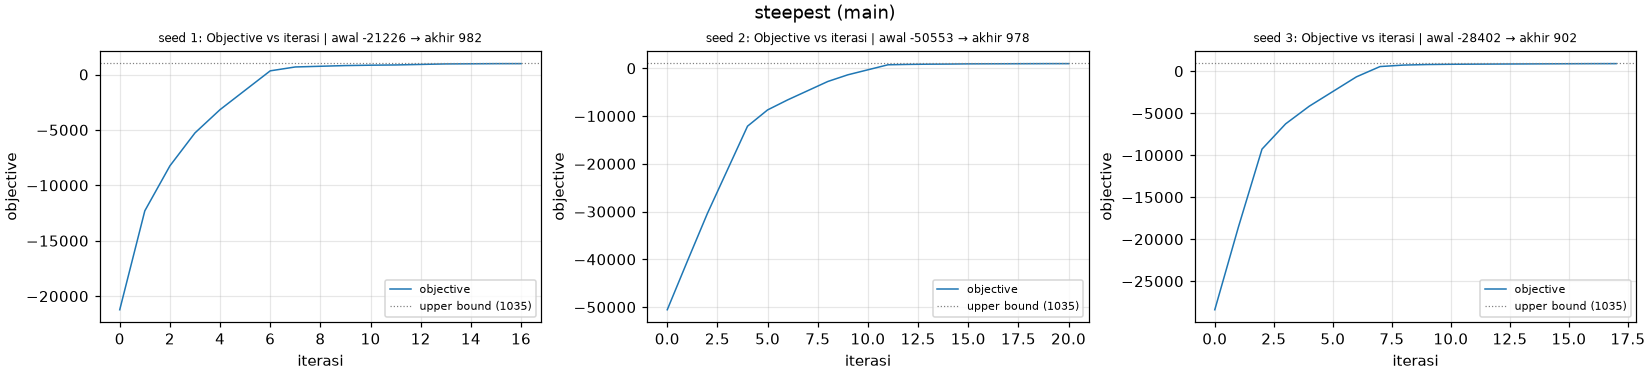

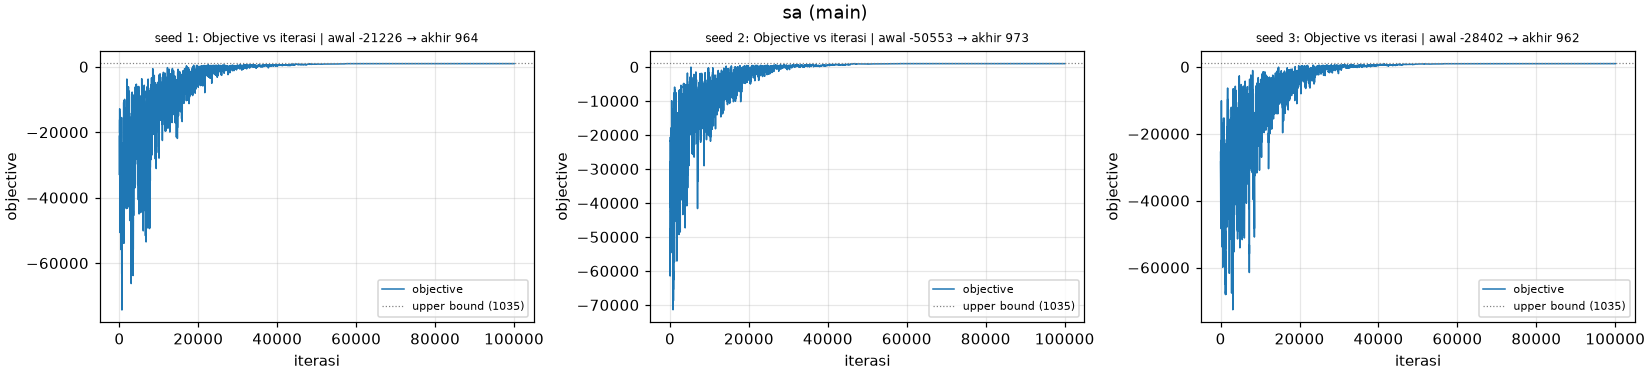

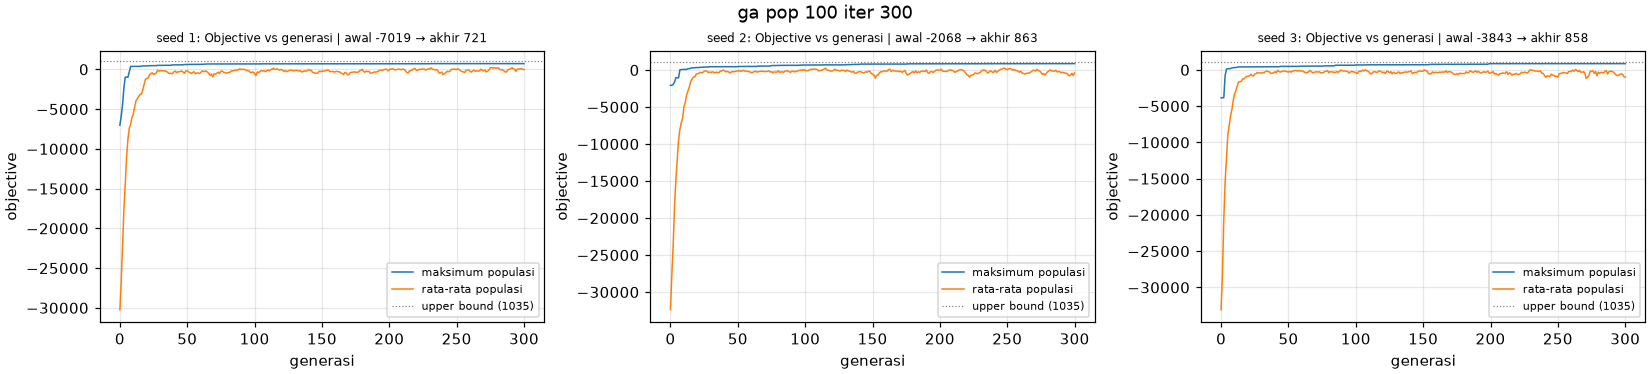

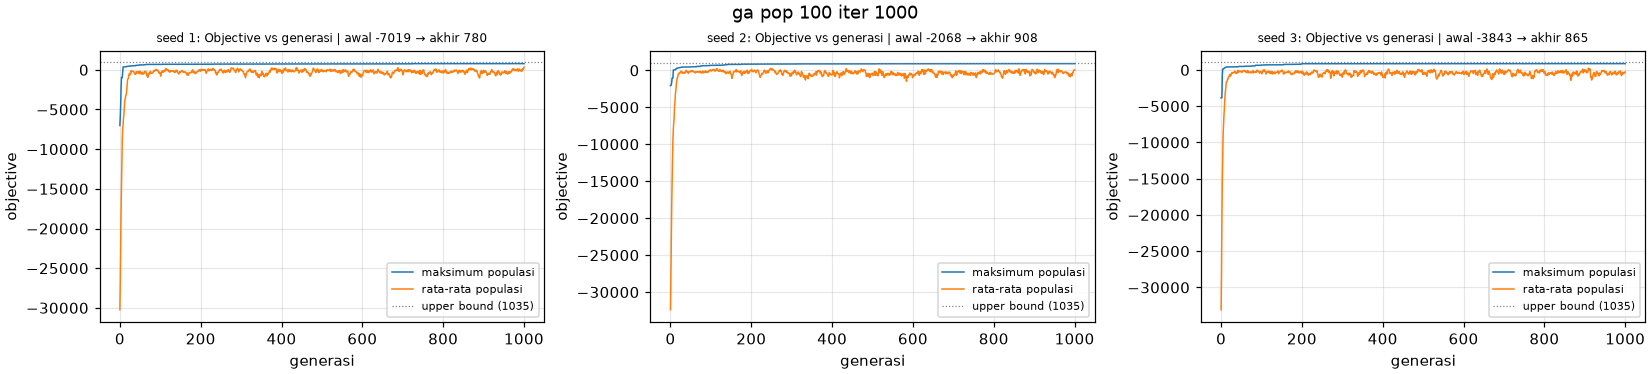

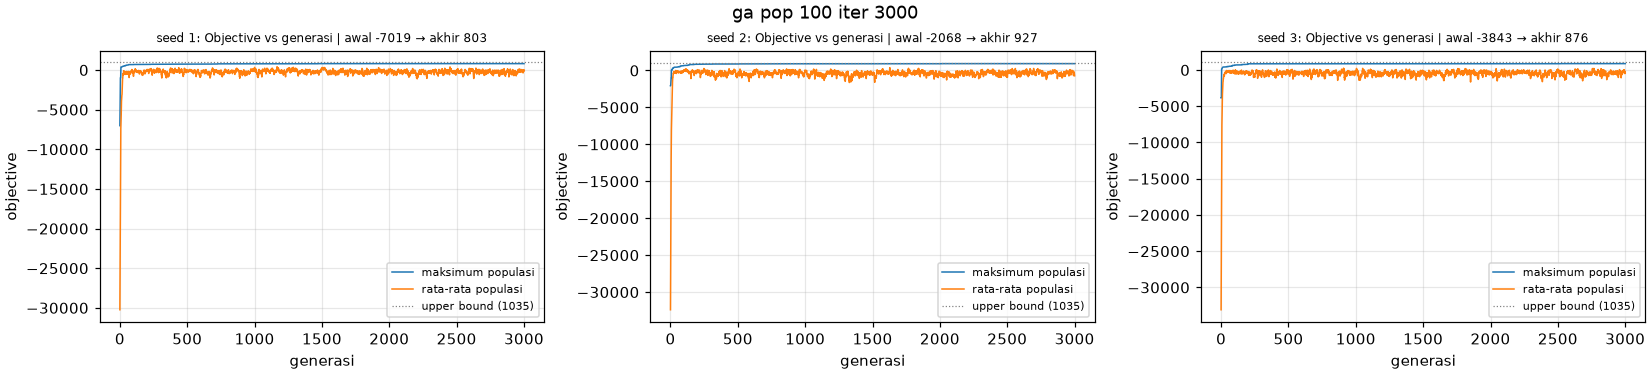

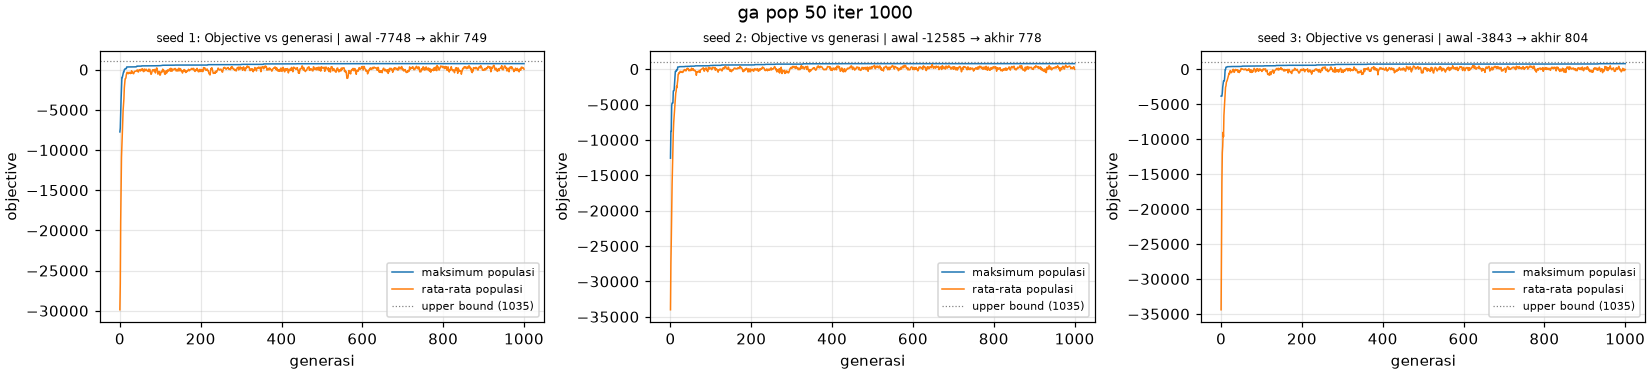

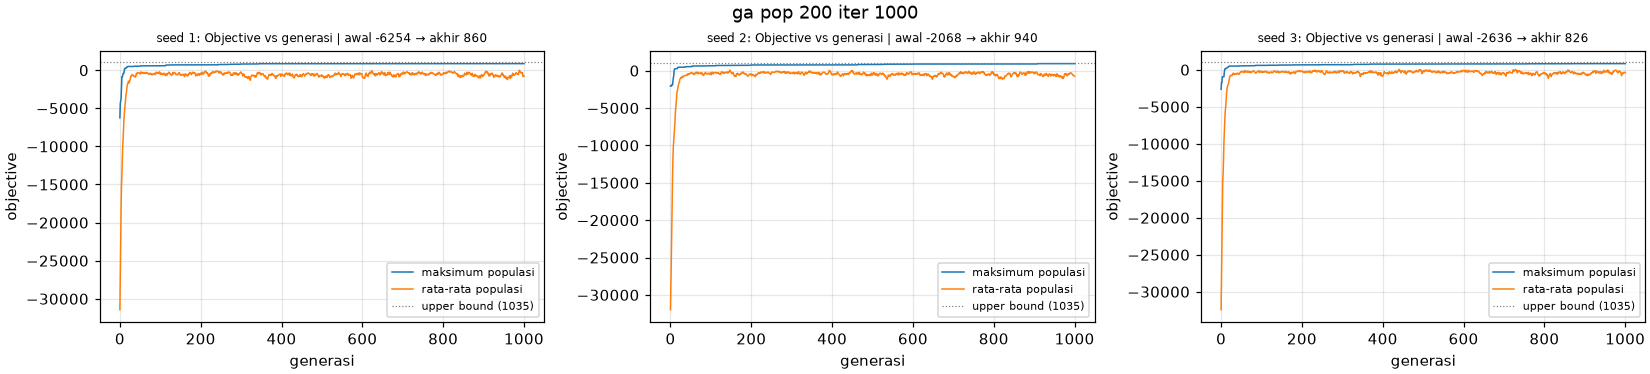

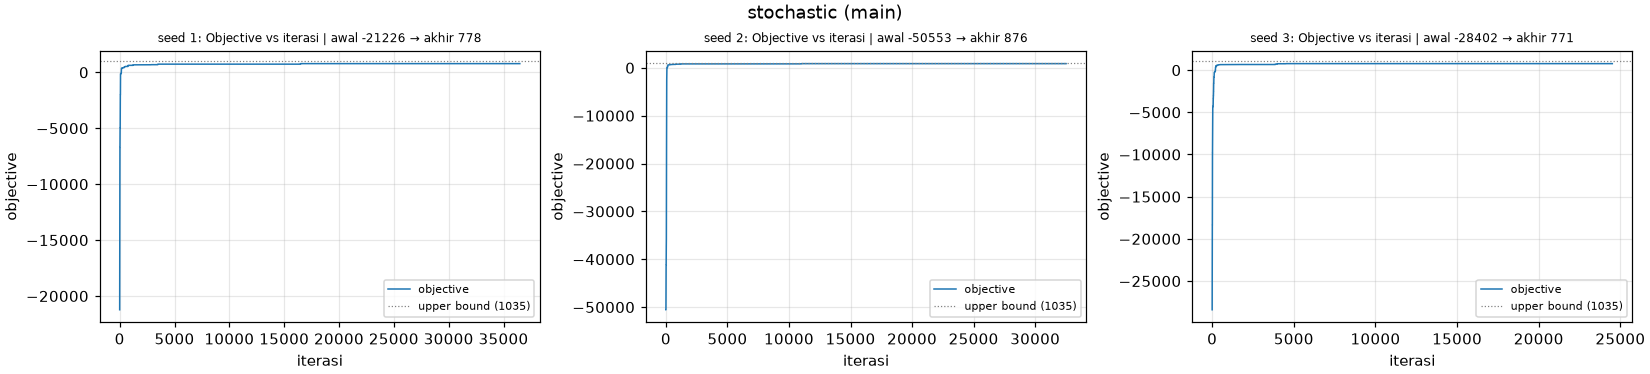

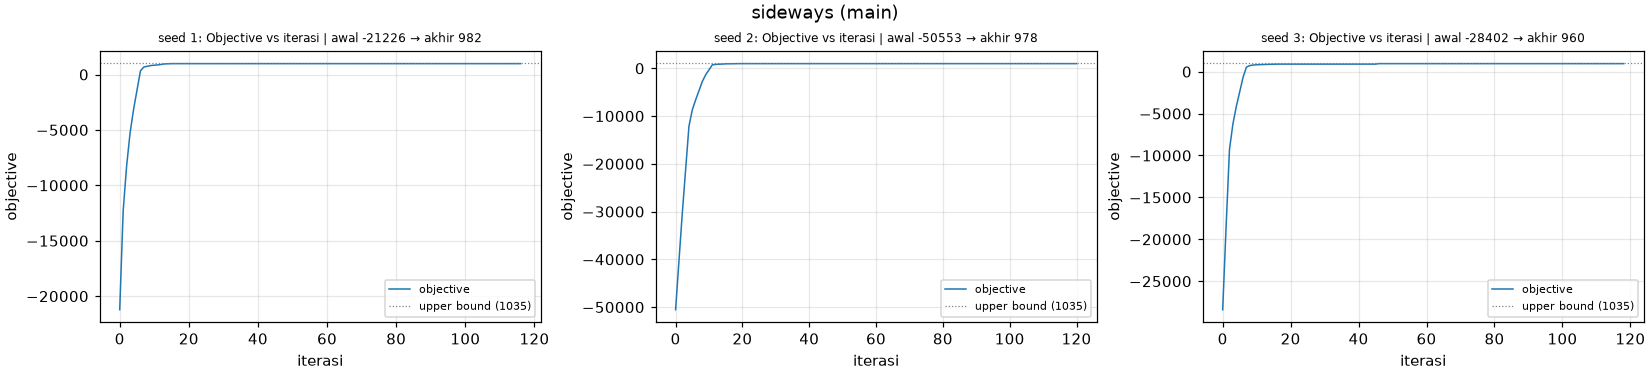

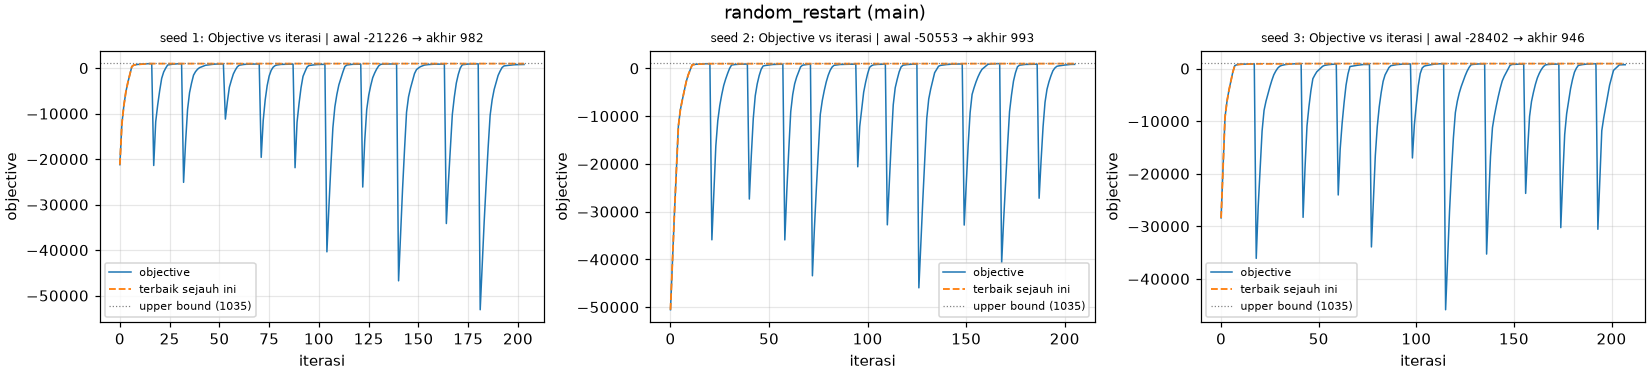

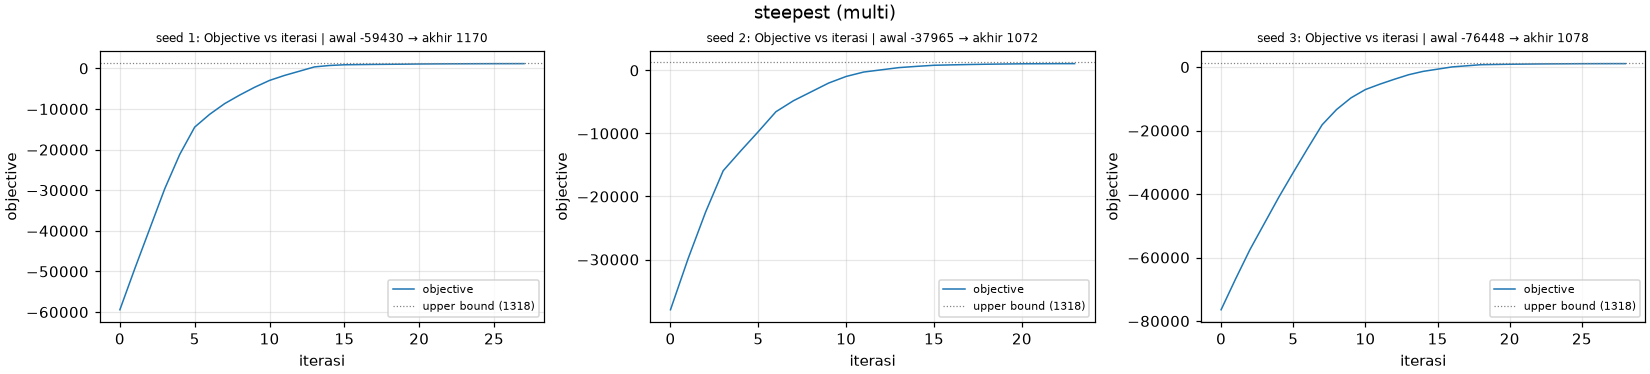

In [4]:
def label(run):
    if run.algo == "ga":
        return f"ga pop {run.params['population']} iter {run.params['iterations']}"
    return f"{run.algo} ({run.instance.stem})"


by_label = {}
for run, result in pairs:
    by_label.setdefault(label(run), []).append(result)

for name, group in by_label.items():
    group = sorted(group, key=lambda r: r["seed"])
    fig = Figure(figsize=(5 * len(group), 3.4), layout="constrained")
    for ax, result in zip(fig.subplots(1, len(group), squeeze=False)[0], group):
        plot_objective(ax, result)
        ax.set_title(f"seed {result['seed']}: {ax.get_title()}", fontsize=8)
    fig.suptitle(name)
    show(fig)

### 3b. Simulated Annealing: objective dan `e^(ΔE/T)`

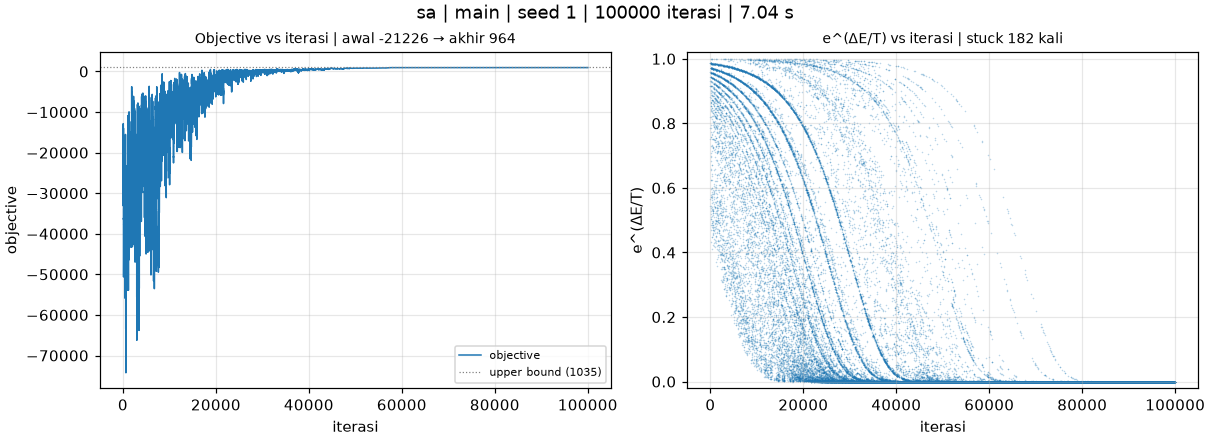

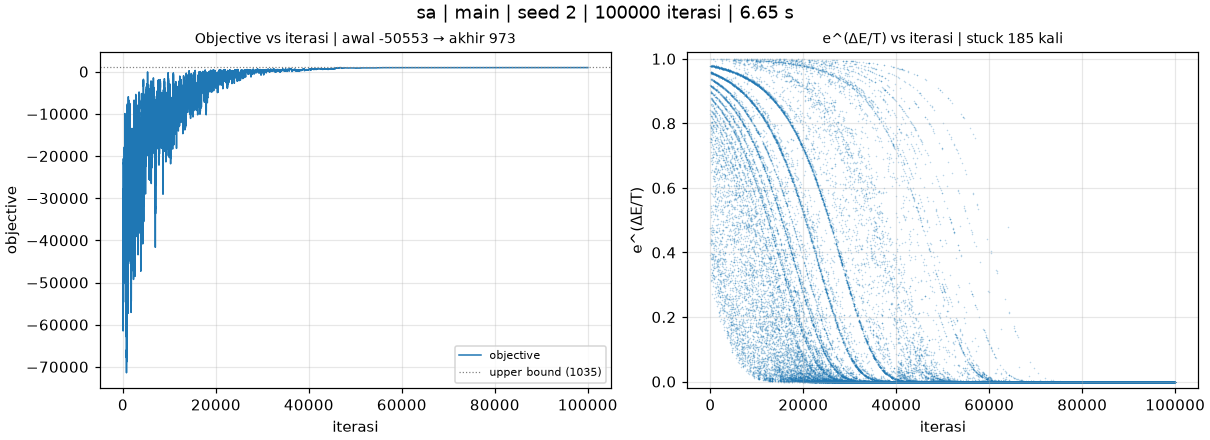

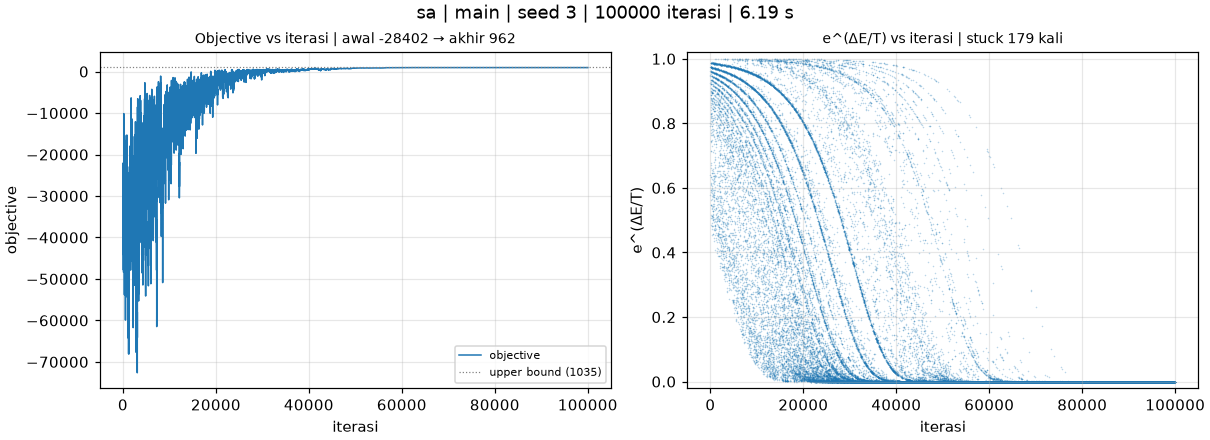

In [5]:
for run, result in pairs:
    if run.algo == "sa":
        show(plot_run(result))

## 4. State awal dan akhir run terbaik tiap algoritma

Run terbaik = objective akhir tertinggi di antara seed. Panel per geladak (multi-kapal: satu panel per kapal),
ditambah daftar kendaraan di luar kapal.

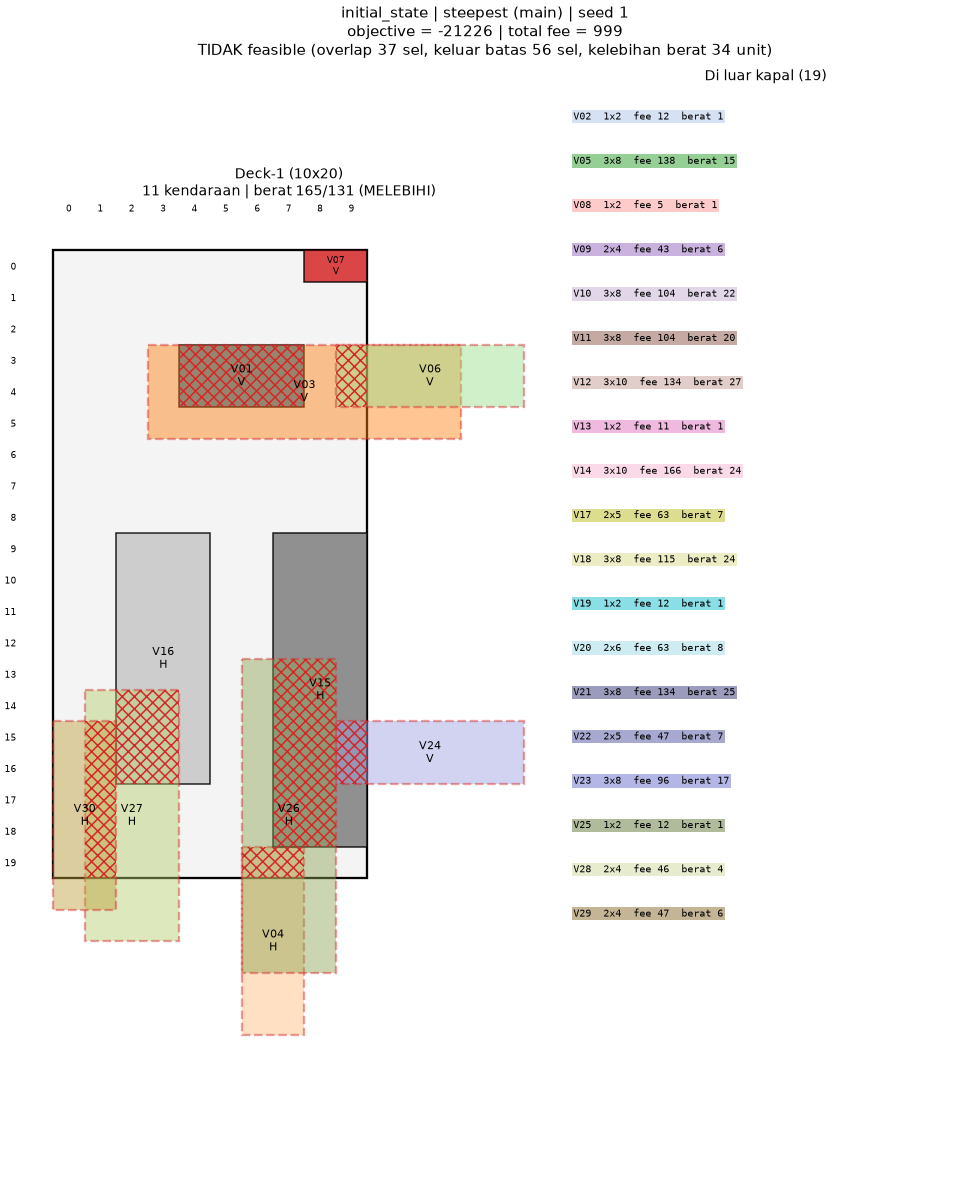

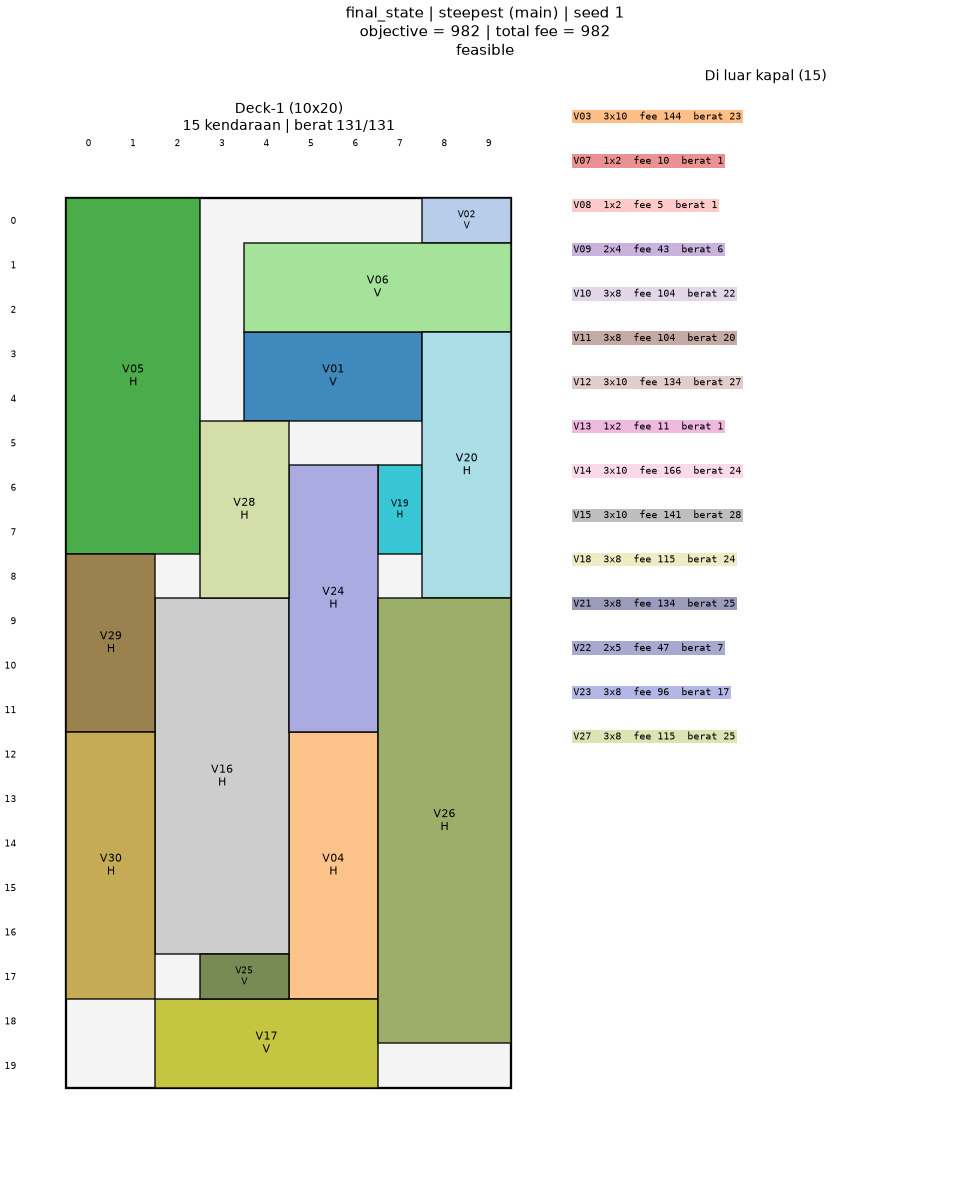

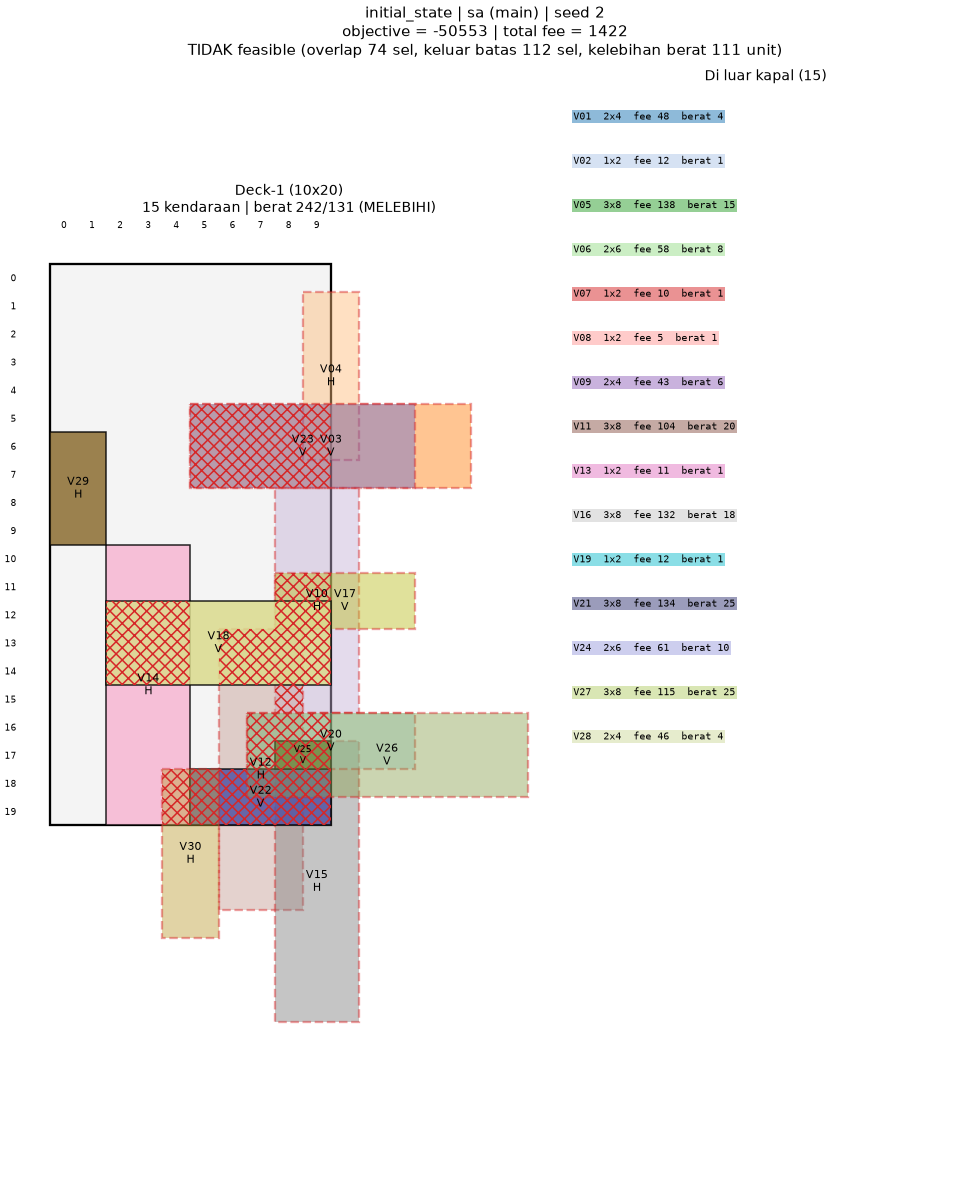

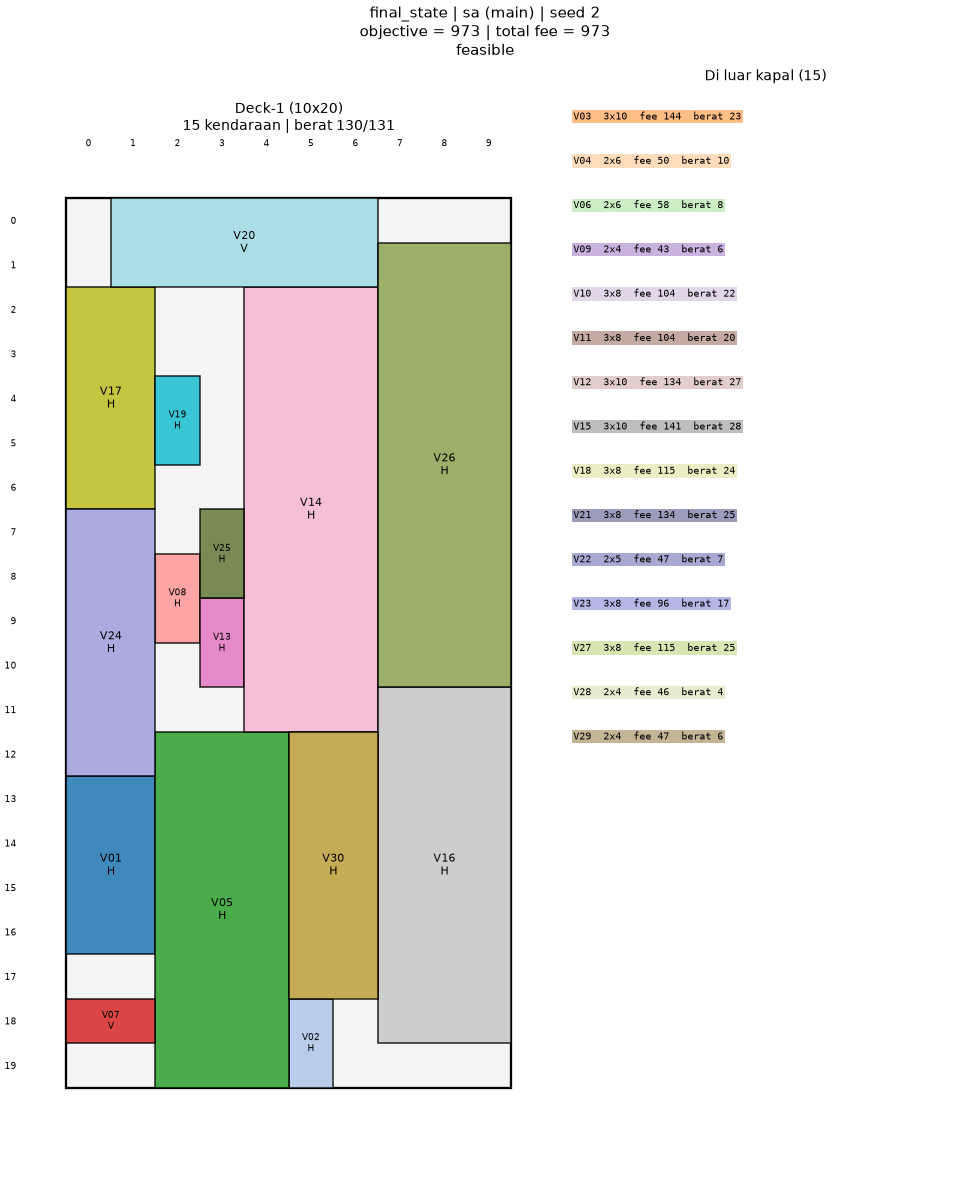

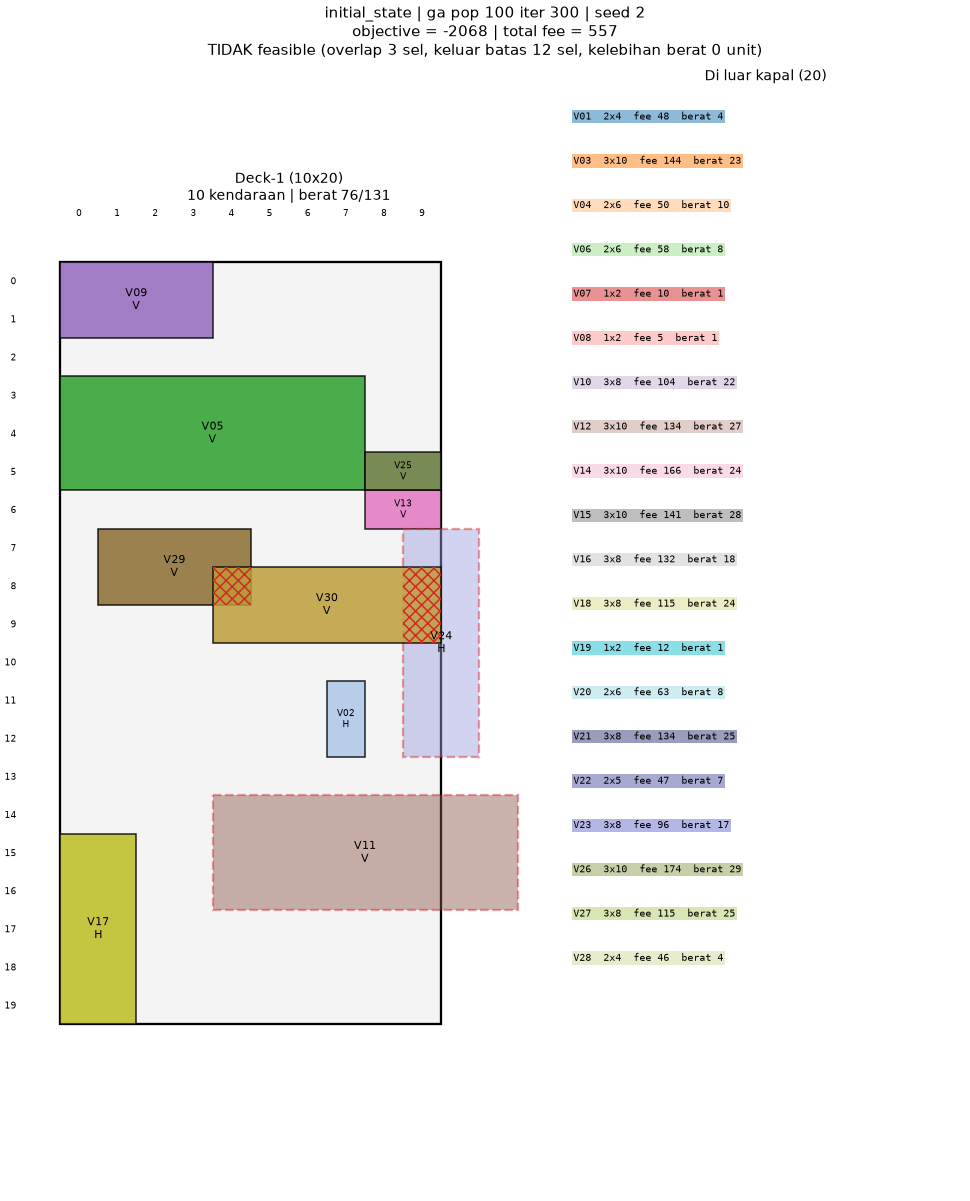

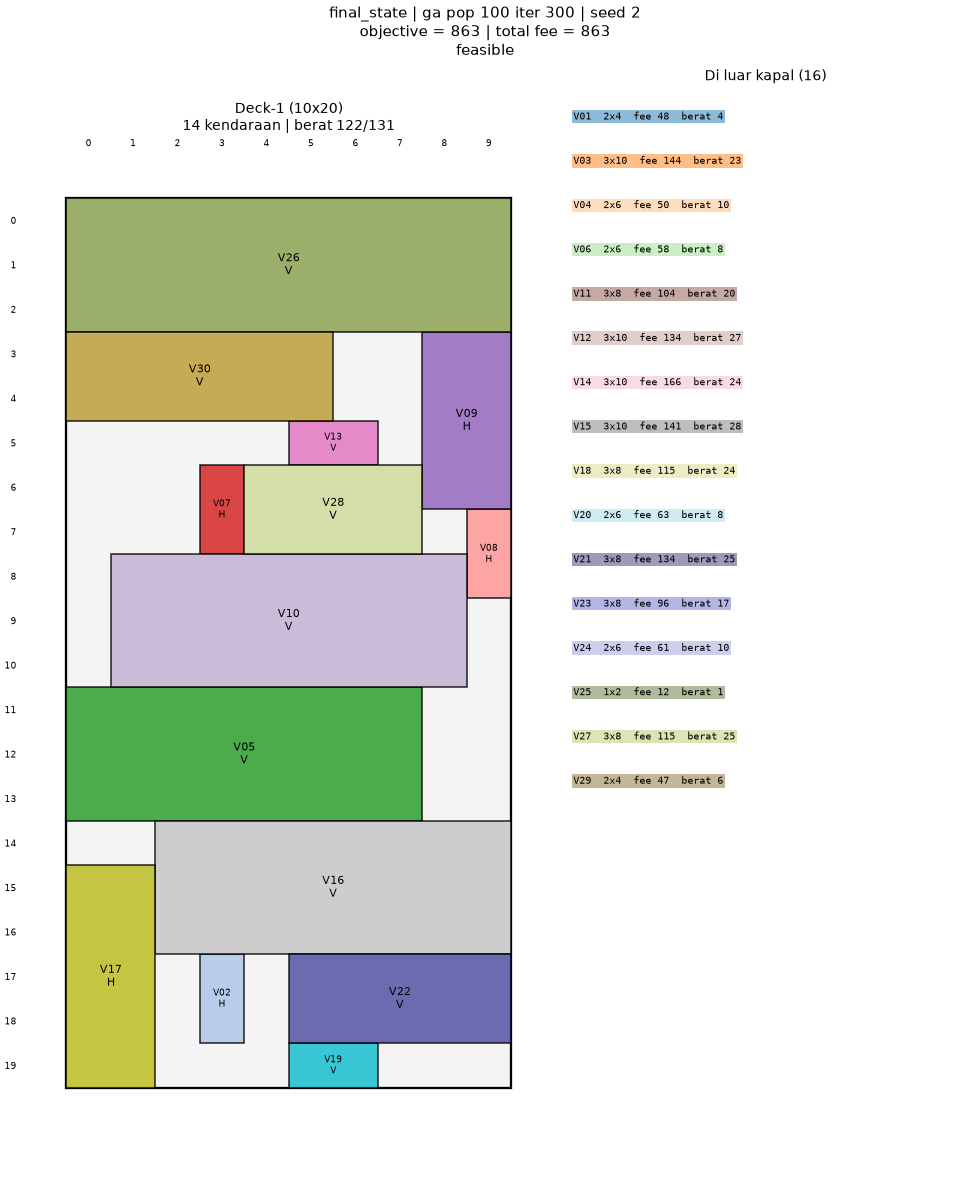

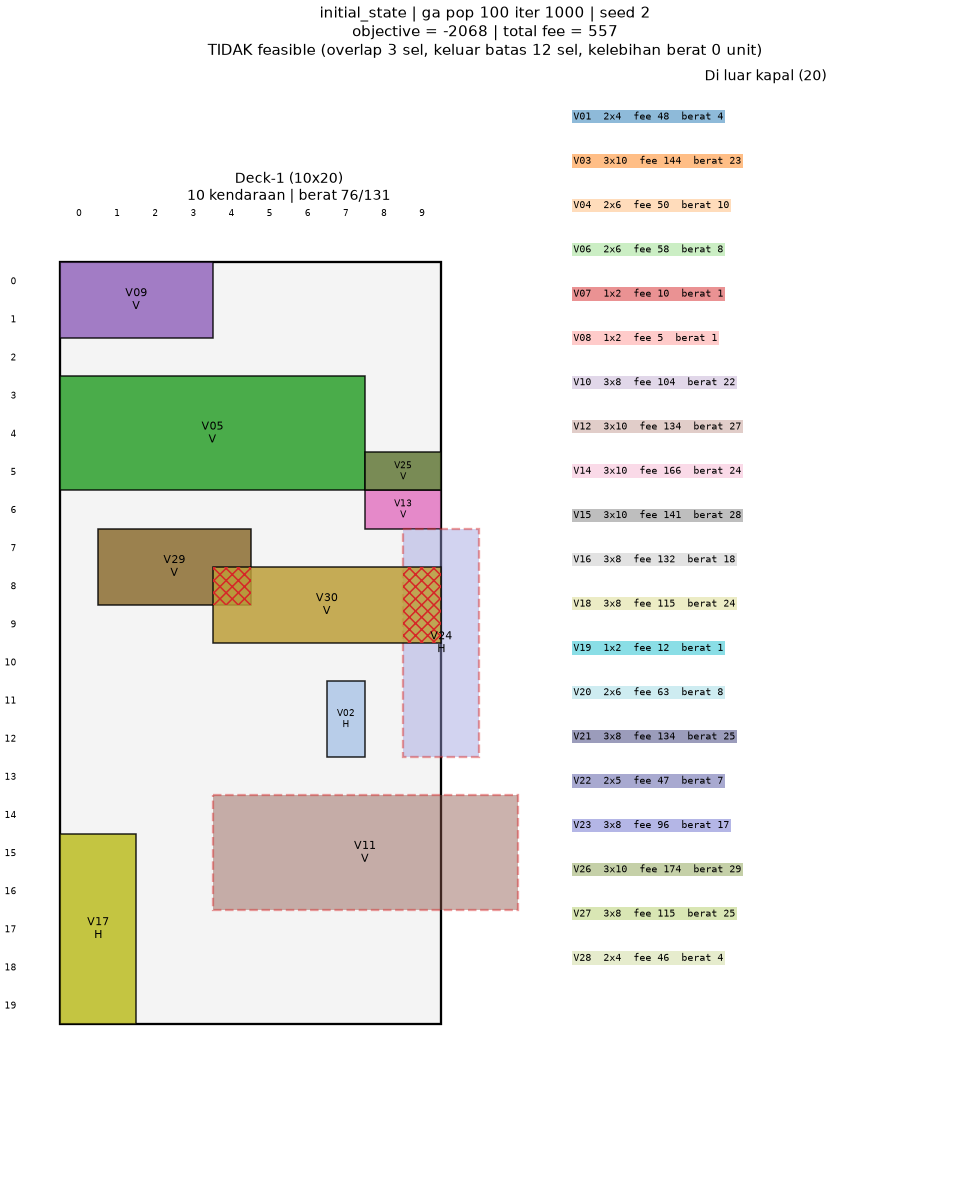

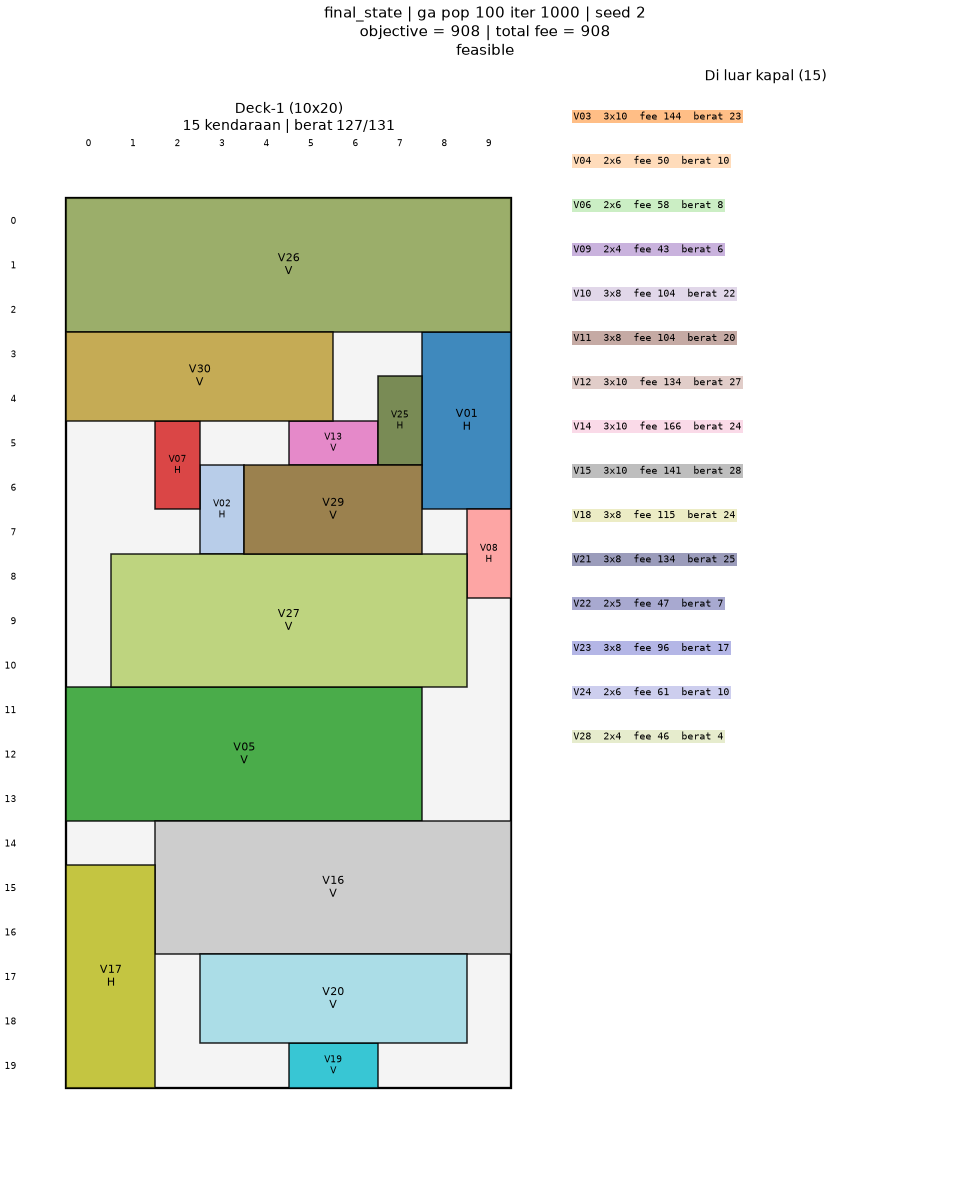

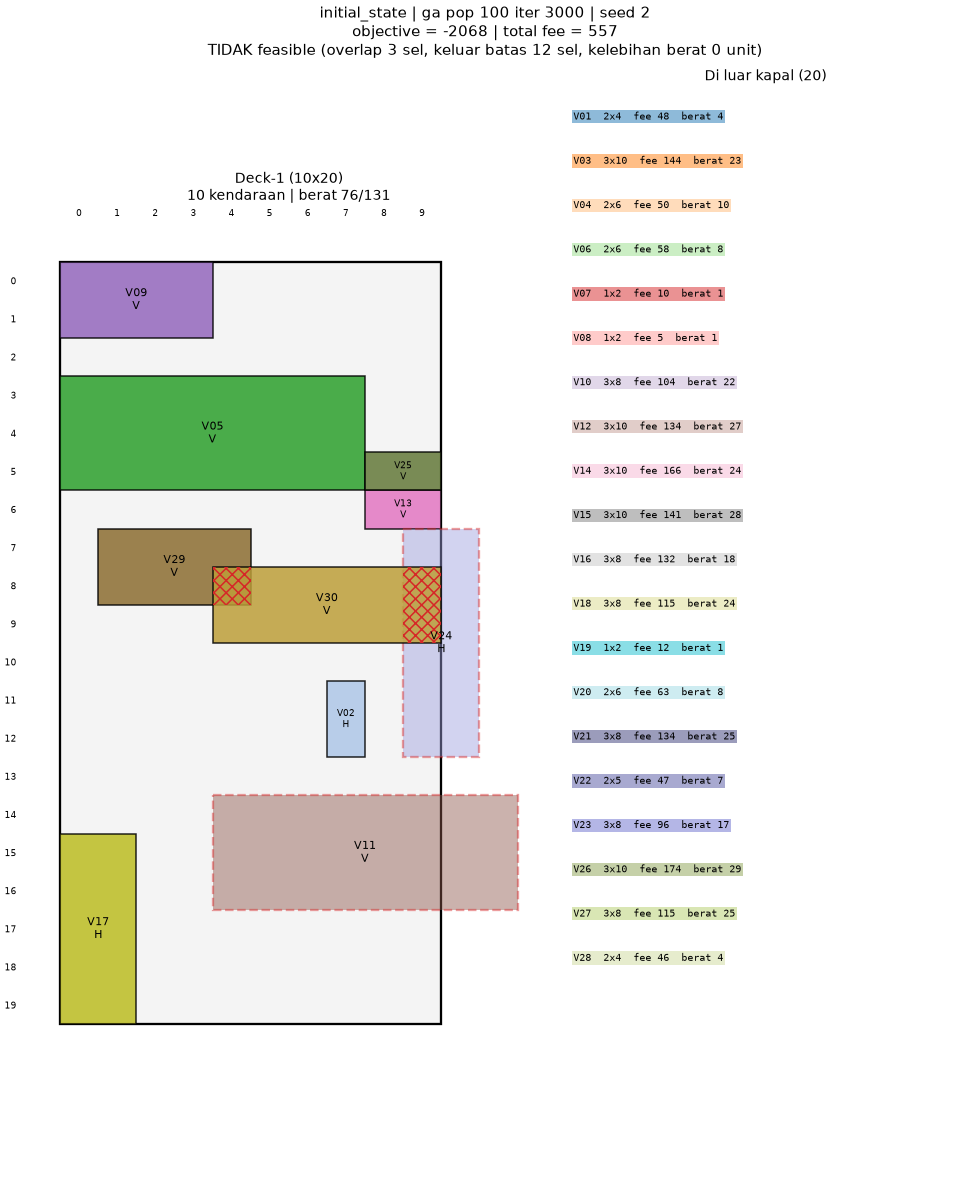

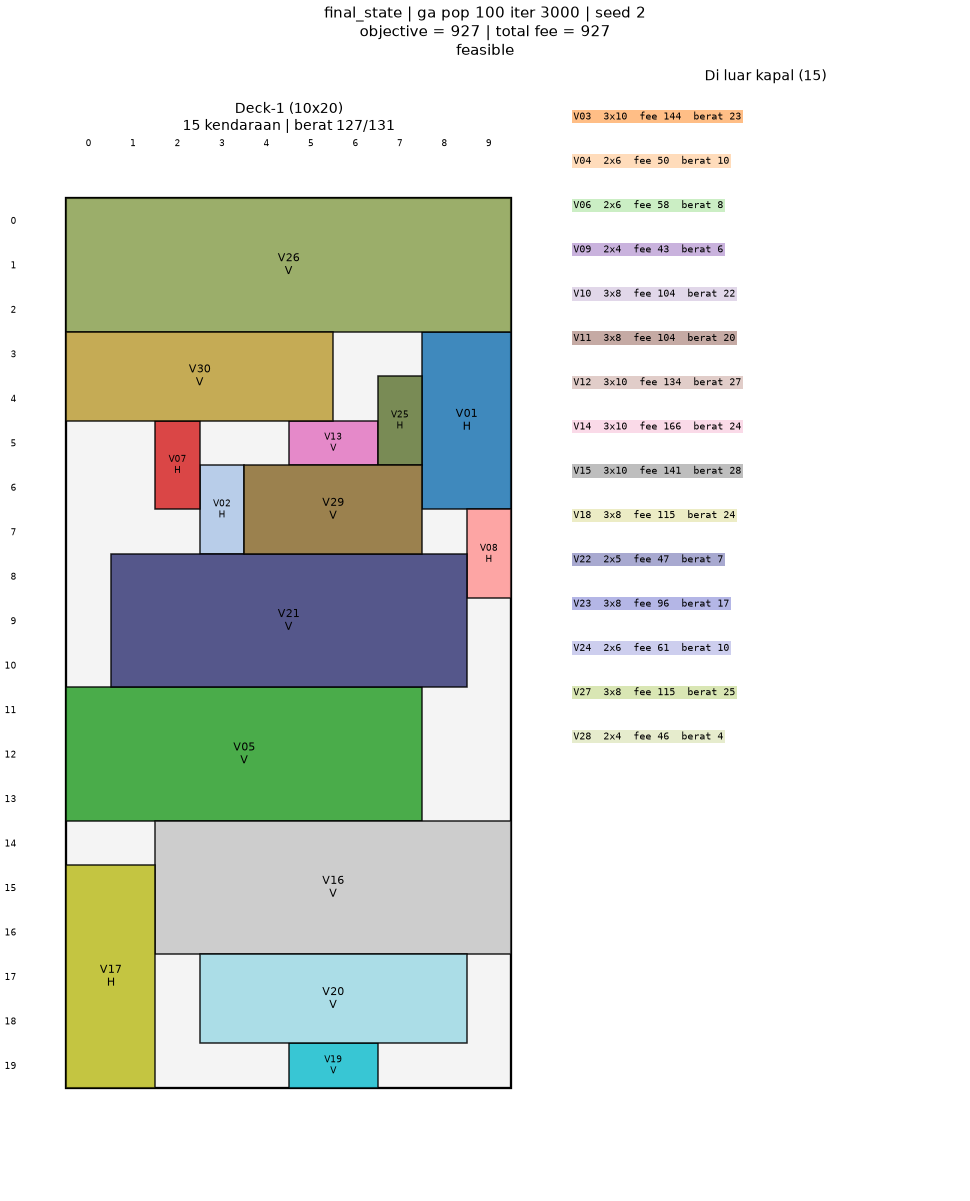

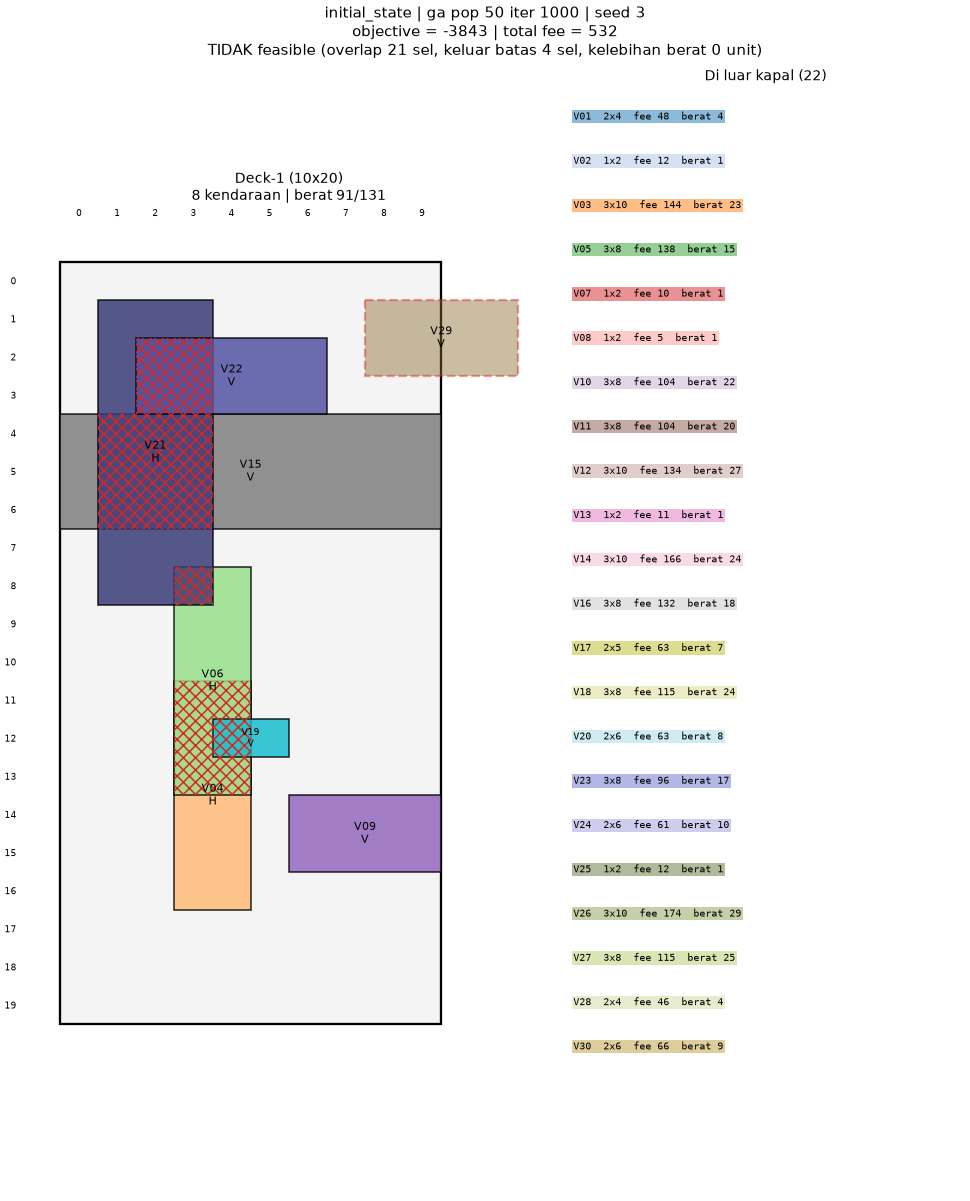

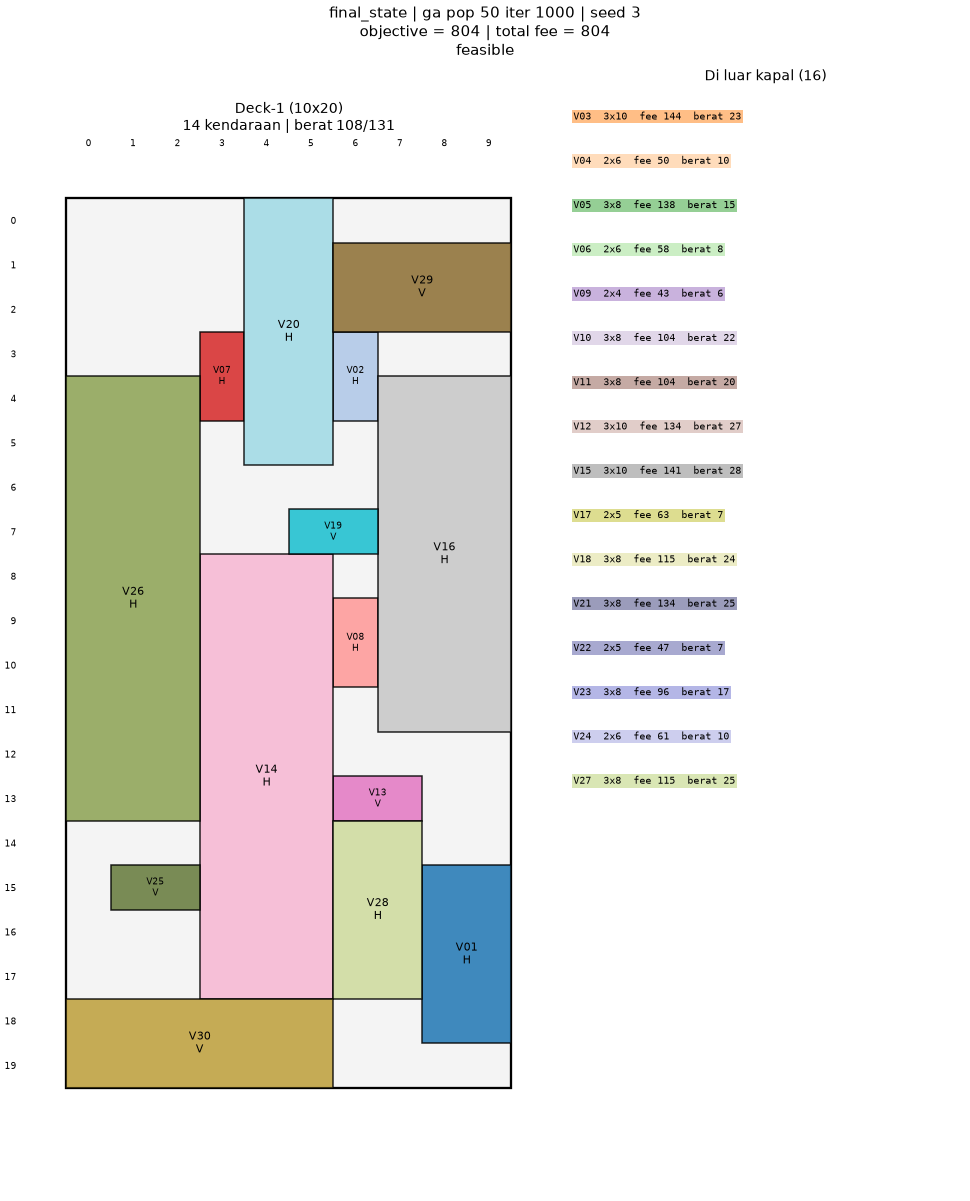

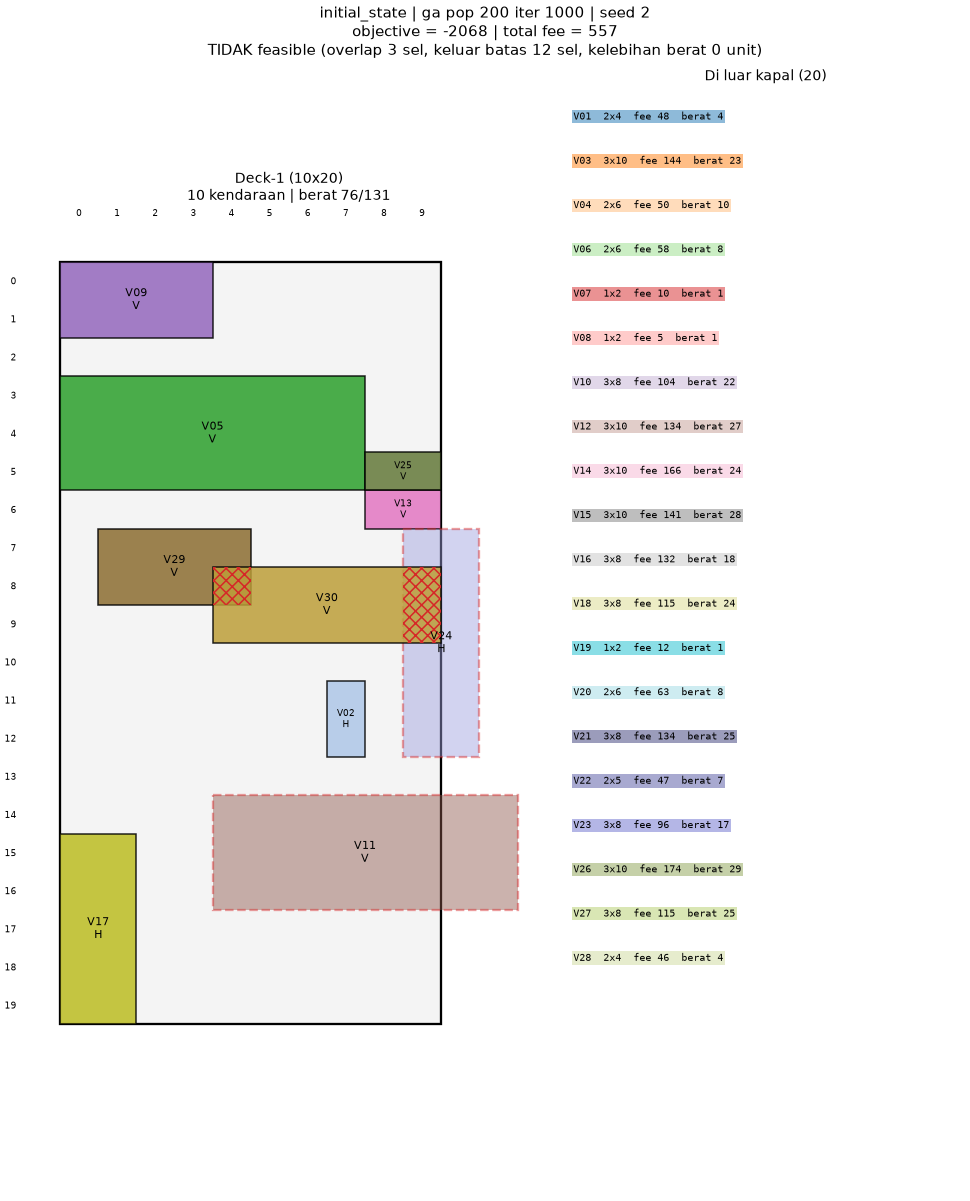

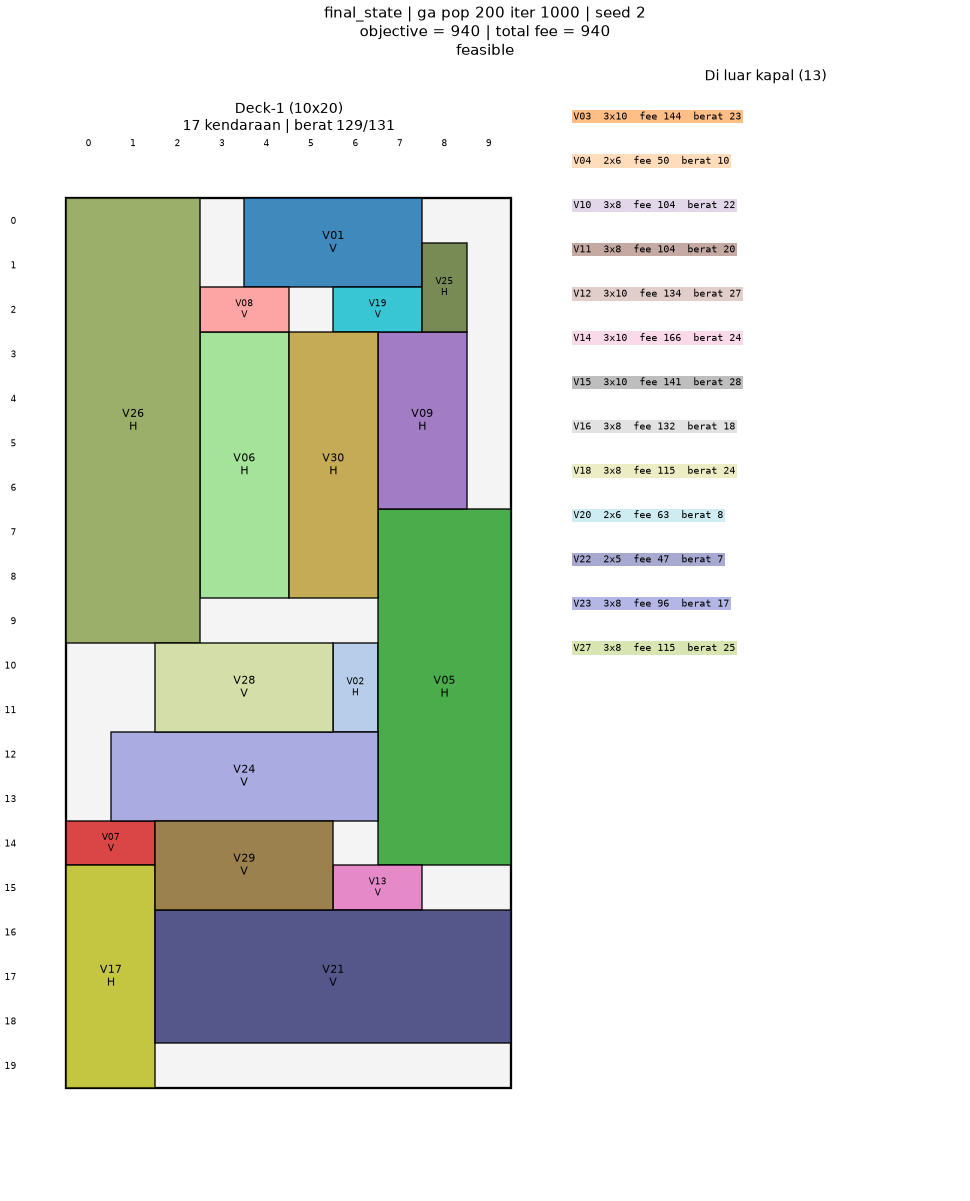

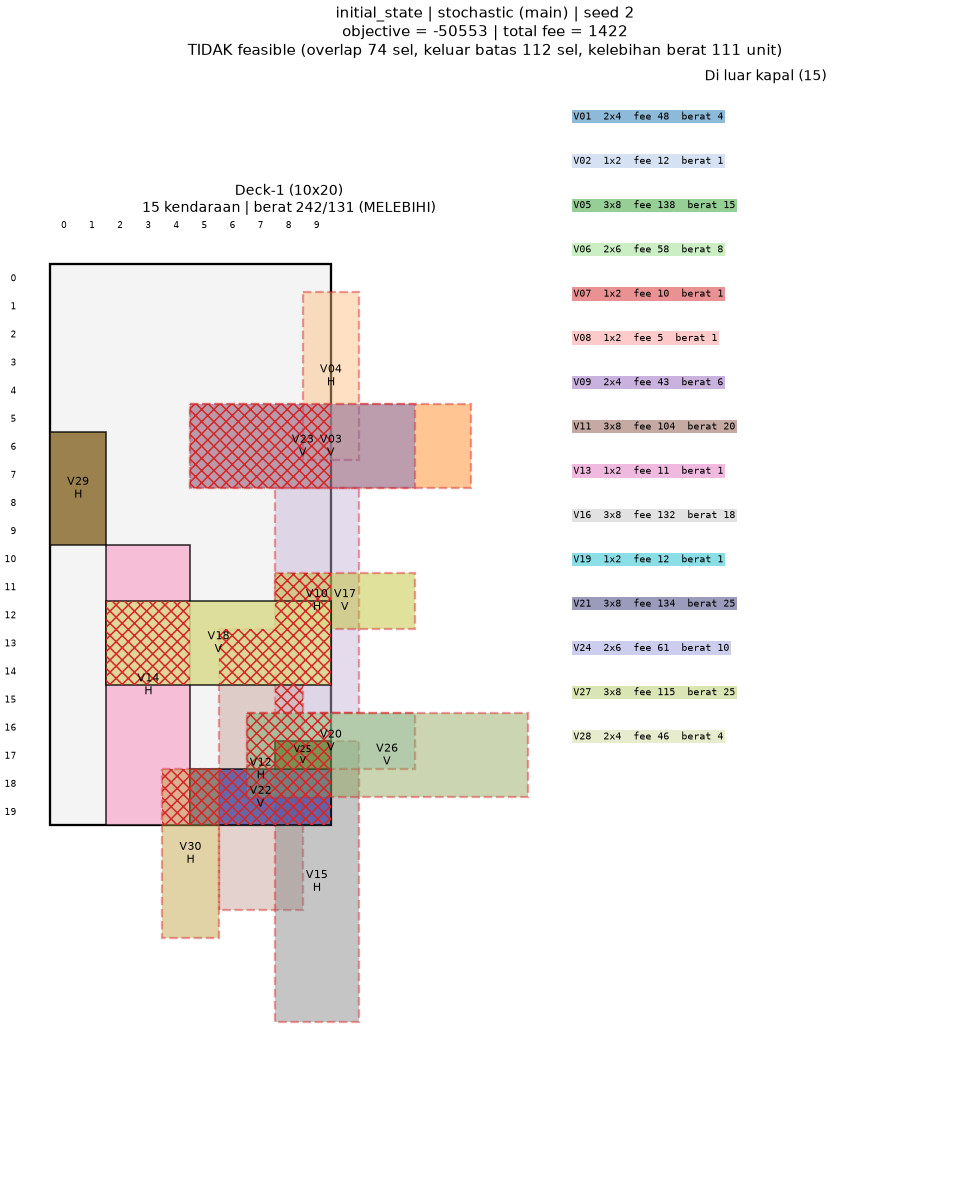

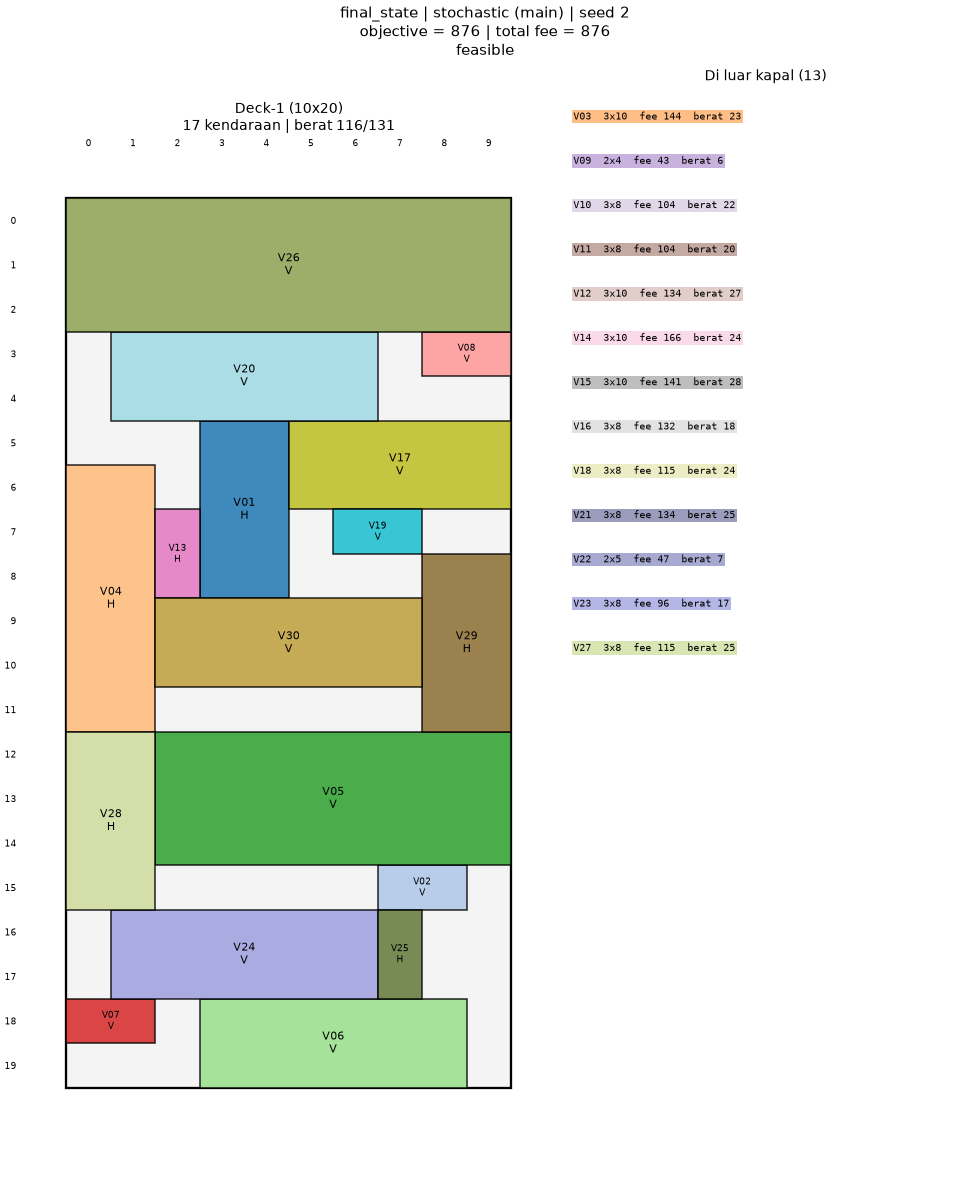

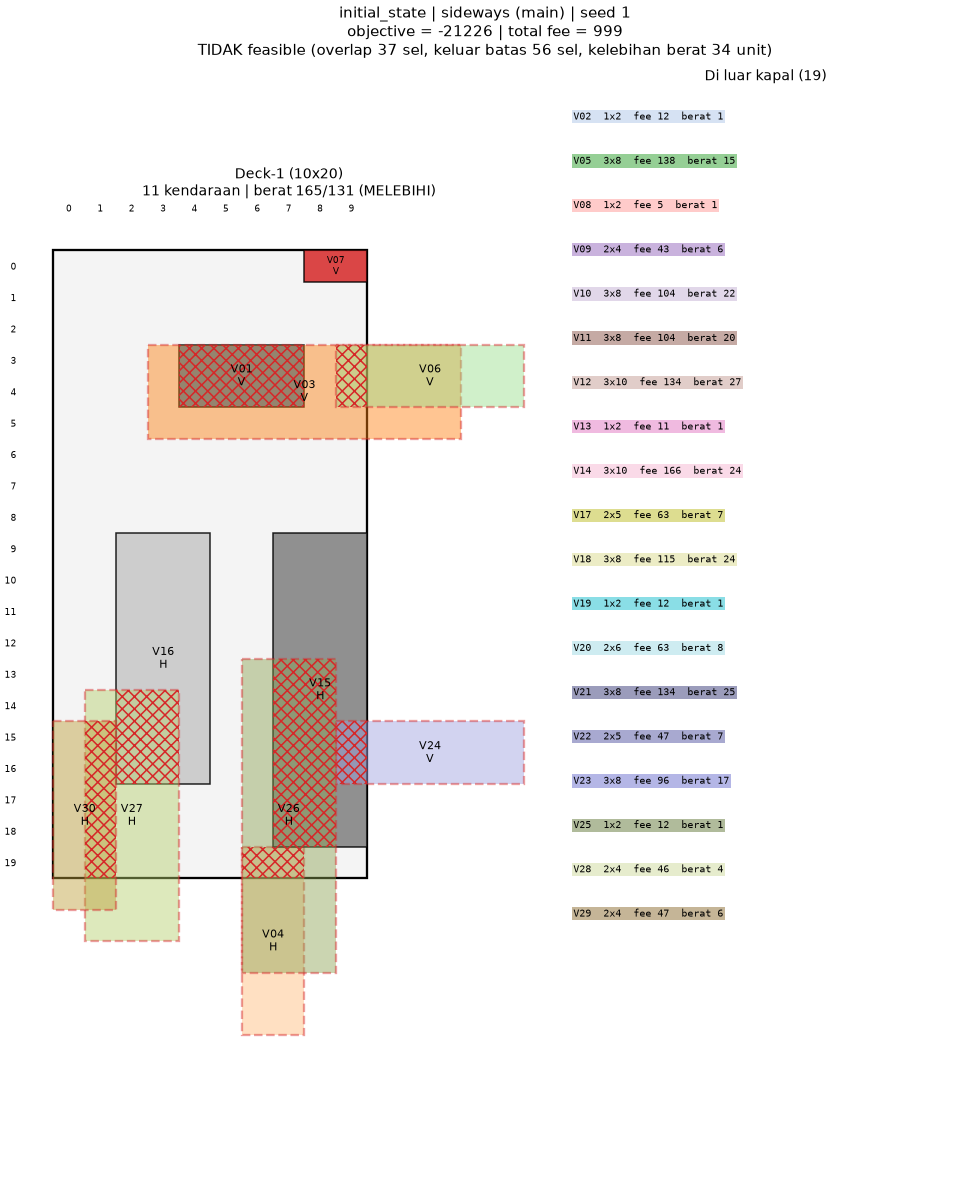

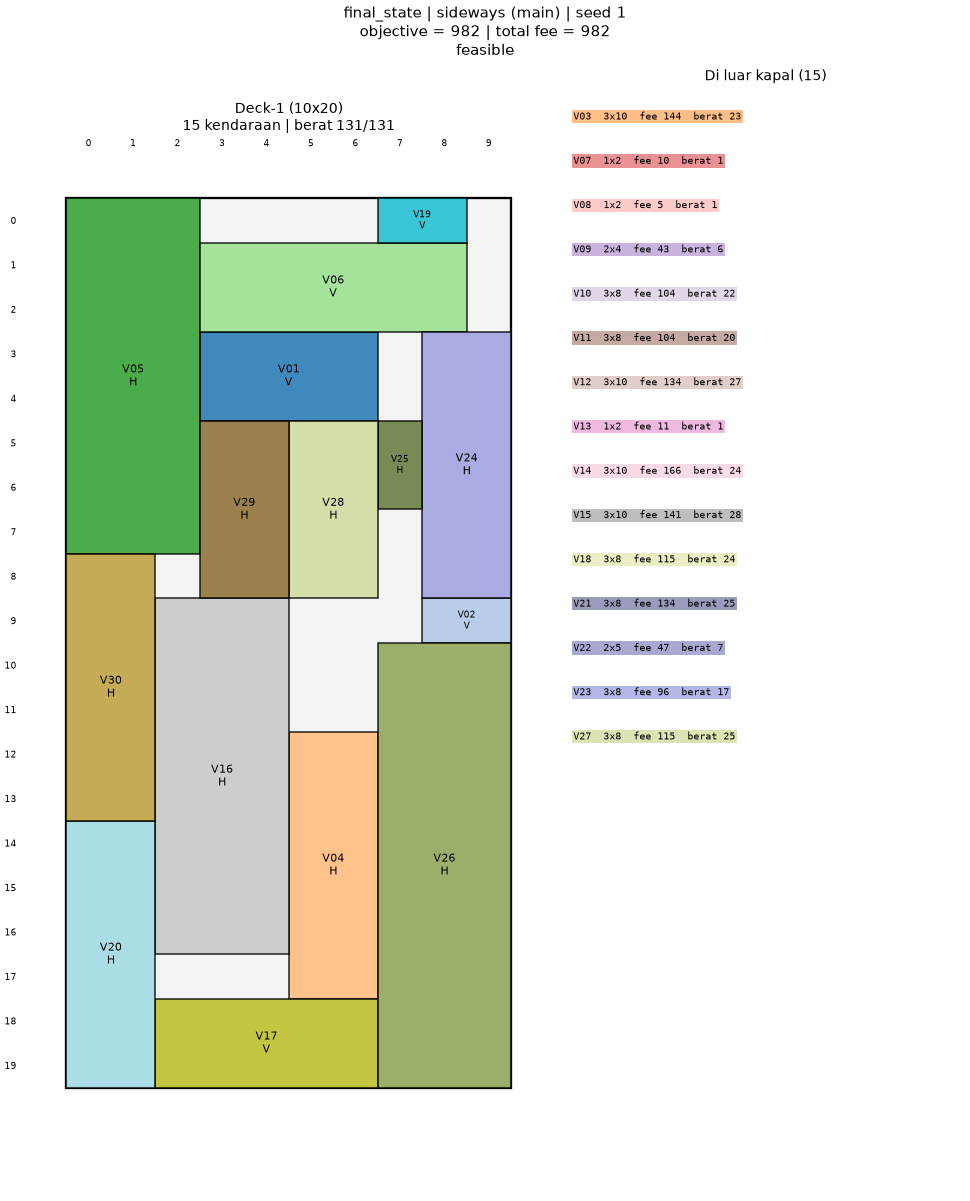

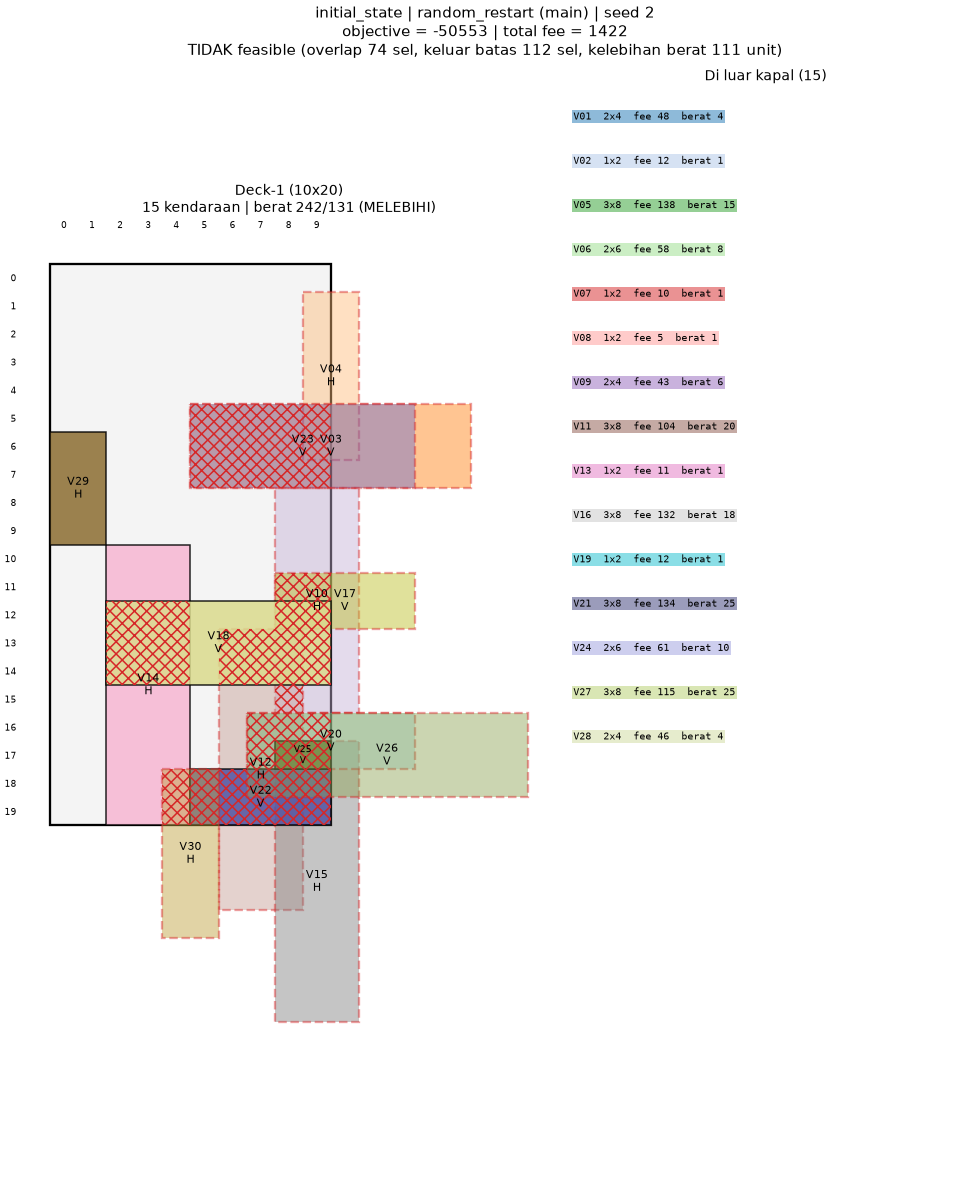

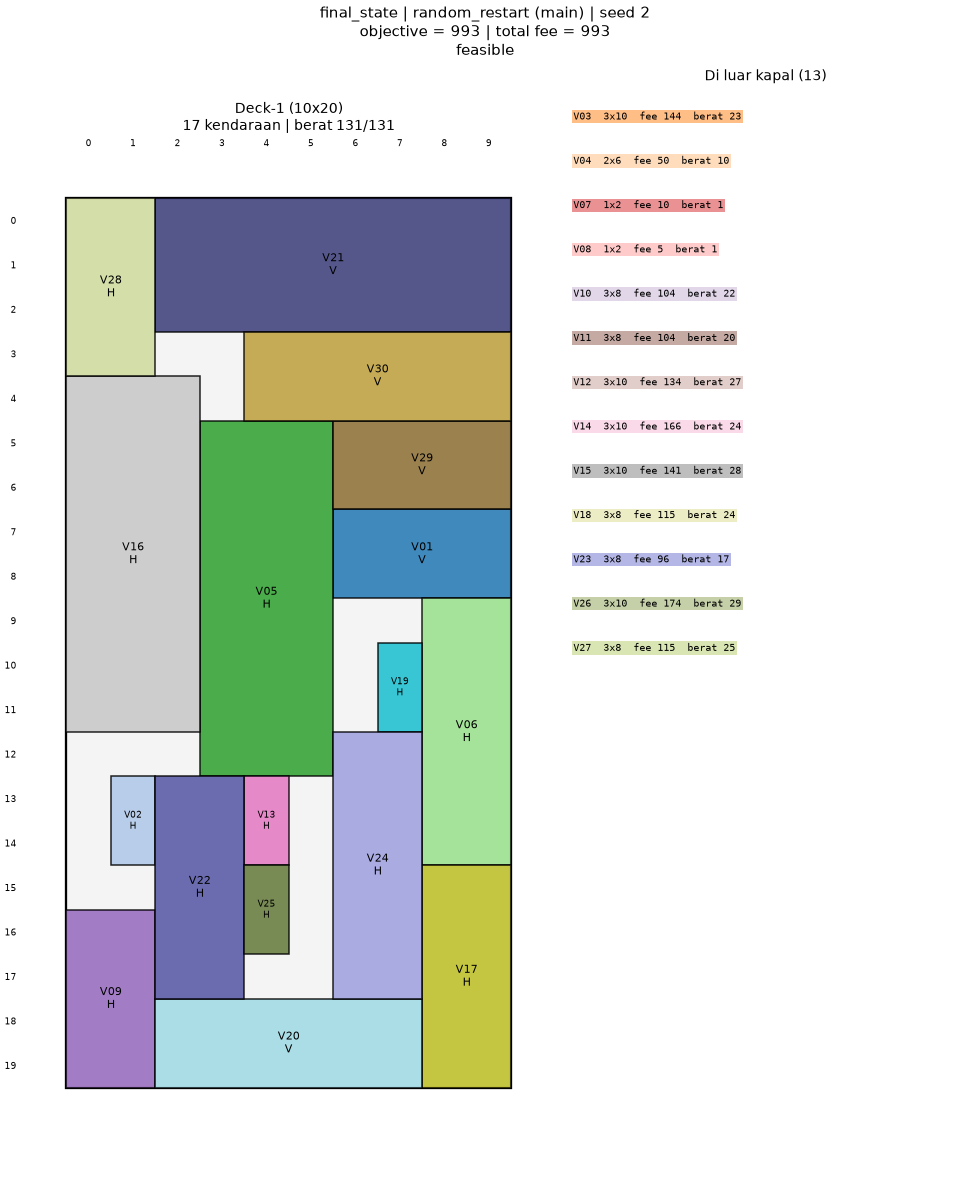

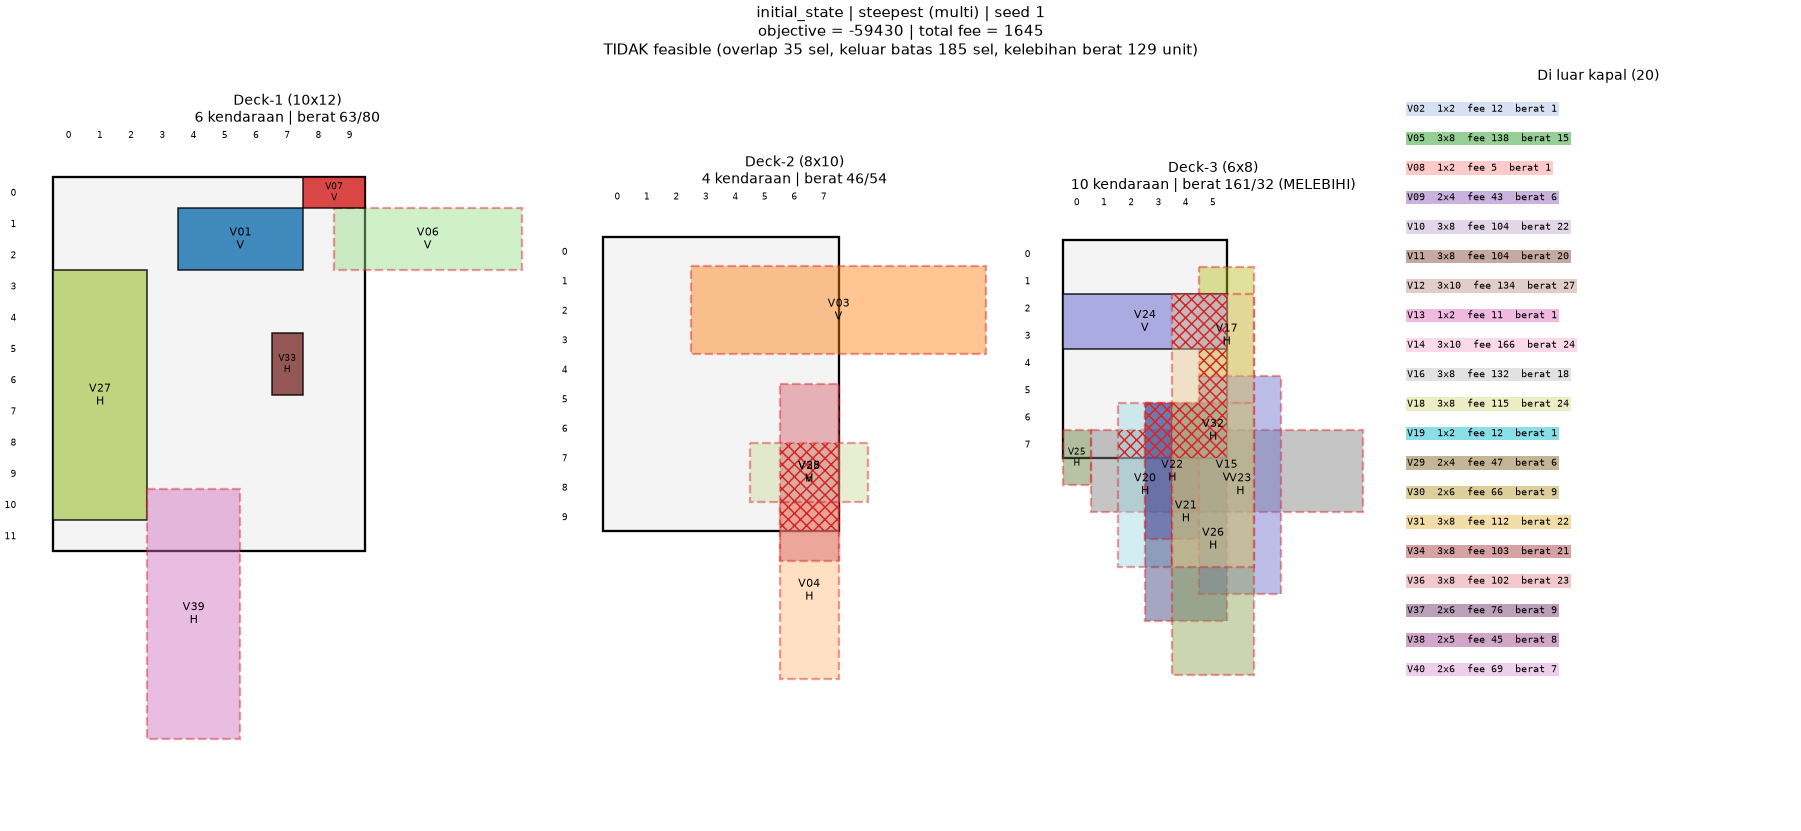

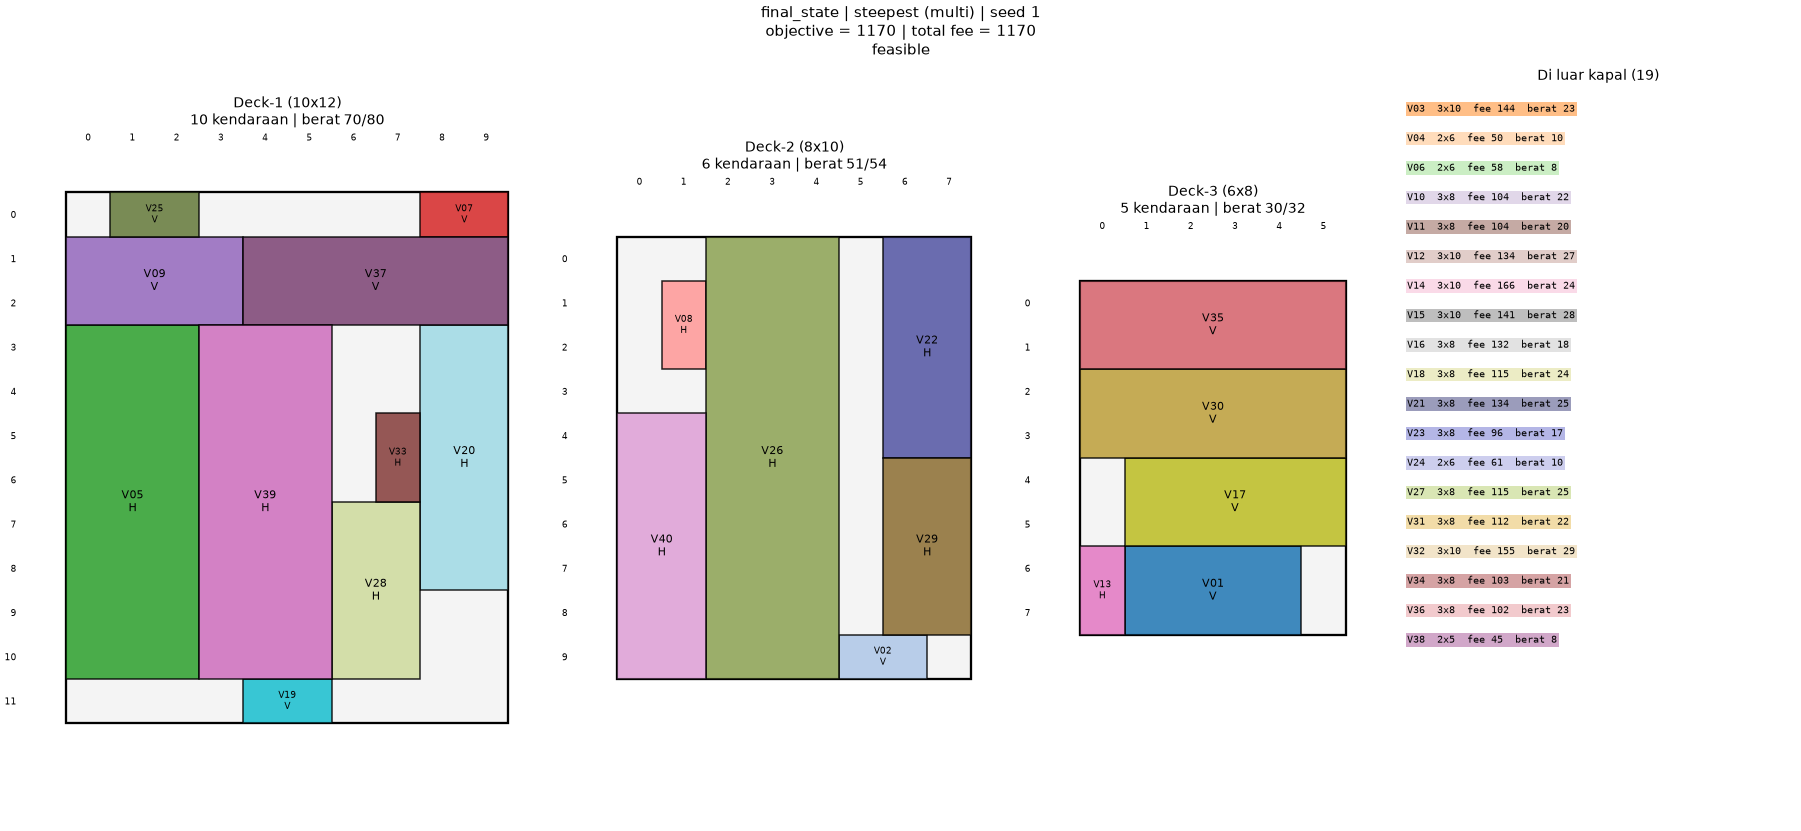

In [6]:
problems = {}
best = {}
for run, result in pairs:
    if run.objective != "fee":
        continue
    name = label(run)
    if name not in best or result["final_objective"] > best[name][1]["final_objective"]:
        best[name] = (run, result)

for name, (run, result) in best.items():
    problem = problems.setdefault(run.instance, load_problem(run.instance))
    for key in ("initial_state", "final_state"):
        show(draw_state(problem, result[key], title=f"{key} | {name} | seed {result['seed']}"))

## 5. Ringkasan antar-algoritma

Box plot objective akhir (titik = tiap run) dan rata-rata durasi. GA diwakili konfigurasi dengan rata-rata
objective terbaik. Lalu perbandingan konfigurasi GA, dan kurva konvergensi terhadap jumlah evaluasi objective
(lebih adil daripada iterasi, EXPERIMENTS §1).

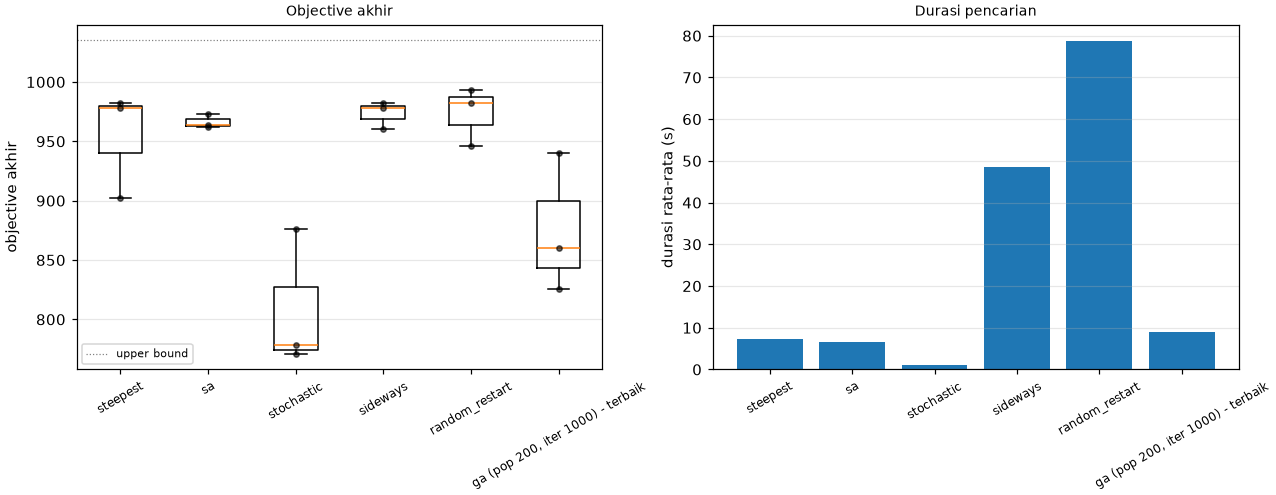

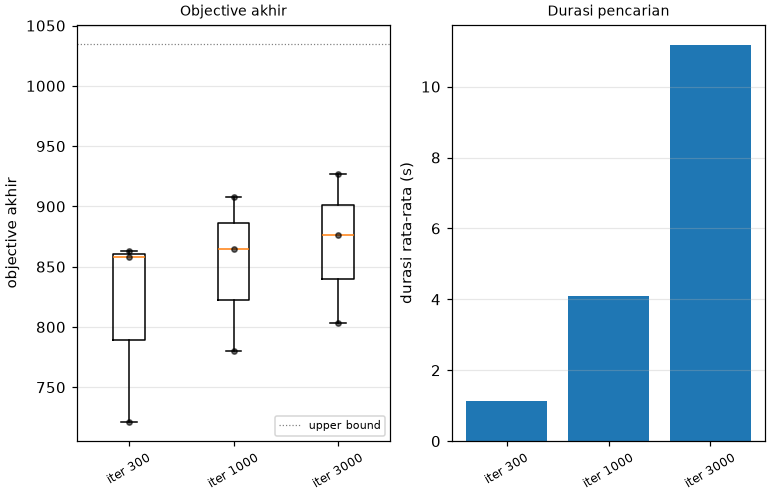

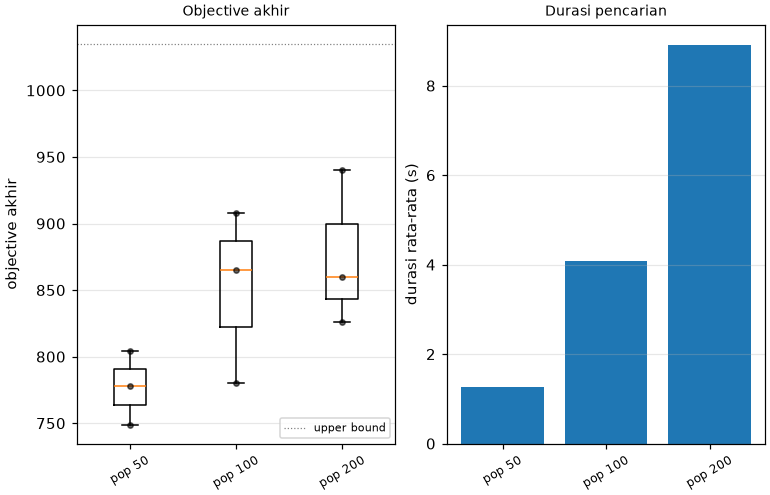

In [7]:
compare = comparison_groups(pairs)
if compare:
    owner = {id(r): name for name, group in compare.items() for r in group}
    show(plot_summary([r for group in compare.values() for r in group], group=lambda r: owner[id(r)]))

for group, key, name in (("ga_iter", "iterations", "iter"), ("ga_pop", "population", "pop")):
    results_ga = sorted((res for run, res in pairs if group in run.groups), key=lambda r: r["params"][key])
    if results_ga:
        show(plot_summary(results_ga, group=lambda r: f"{name} {r['params'][key]}"))

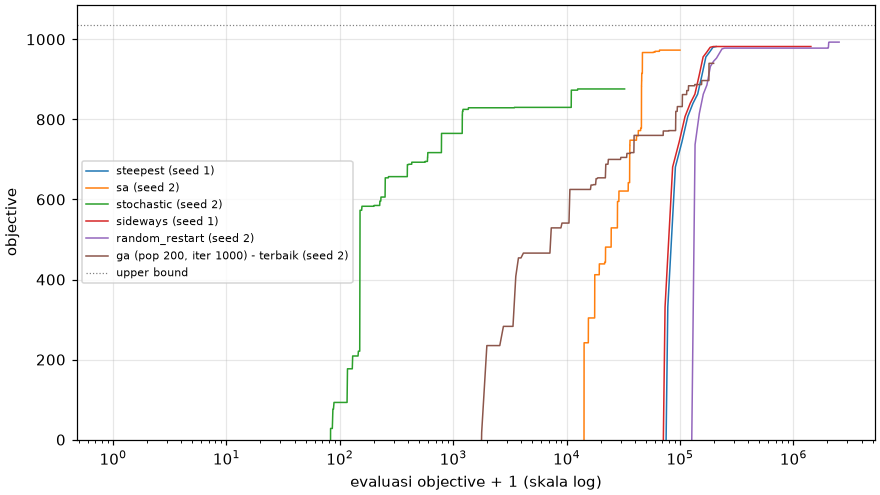

In [8]:
# konvergensi: x = evaluasi objective. Evaluasi dianggap tersebar rata antar-iterasi (pendekatan).
# Sumbu y dibatasi ke 0..UB supaya bagian akhir pencarian terlihat (objective awal bisa sangat negatif).
fig = Figure(figsize=(8, 4.5), layout="constrained")
ax = fig.subplots()
upper = None
for name, group in compare.items():
    result = max(group, key=lambda r: r["final_objective"])
    curve = result["history"].get("best", result["history"]["objective"])
    best_so_far = list(accumulate(curve, max))
    xs = [1 + result["evaluations"] * k / max(1, len(curve) - 1) for k in range(len(curve))]
    ax.plot(xs, best_so_far, linewidth=1, label=f"{name} (seed {result['seed']})")
    upper = result["upper_bound"]
if upper is not None:
    ax.axhline(upper, color="gray", linestyle=":", linewidth=0.8, label="upper bound")
    ax.set_ylim(0, upper * 1.05)
ax.set_xscale("log")
ax.set_xlabel("evaluasi objective + 1 (skala log)")
ax.set_ylabel("objective")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)
show(fig)

## 6. Analisis

Isi bagian ini Rabu 21 setelah run resmi selesai, mengikuti checklist EXPERIMENTS §5:

- perbandingan objective akhir terhadap upper bound (gap) antar-algoritma,
- kecepatan konvergensi (iterasi dan evaluasi) dan durasi,
- konsistensi hasil antar-seed,
- pengaruh populasi dan banyak iterasi pada GA,
- frekuensi stuck dan peluang `e^(ΔE/T)` pada SA,
- varian HC (Bonus 2) dan multi-kapal (Bonus 3).